# Selección del marcador mitocondrial

Análisis comparativo de los marcadores mitocondriales 12S, 16S y COI para evaluar su capacidad de discriminación entre especies no nativas y especies nativas de contraste.

El análisis considera cuatro componentes principales:

1. Longitud de los marcadores.
2. Variabilidad genética intra e interespecífica mediante p-distance.
3. Resolución taxonómica a nivel de especie.
4. Identificación de regiones discriminatorias para el diseño de primers especie-específicos.


In [20]:
from pathlib import Path
import sqlite3

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from Bio import SeqIO
from itertools import combinations

In [21]:
# =========================
# RUTAS DEL PROYECTO
# =========================

# Carpeta raíz del proyecto
def encontrar_raiz_proyecto():
    actual = Path.cwd().resolve()

    for carpeta in [actual, *actual.parents]:
        db = carpeta / "02_procesamiento" / "tesis.db"
        analisis = carpeta / "04_analisis"

        if db.is_file() and analisis.is_dir():
            return carpeta

    raise FileNotFoundError(
        "No se encontró la raíz del proyecto. "
        "Iniciá Jupyter desde el repositorio o una subcarpeta."
    )

BASE = encontrar_raiz_proyecto()

# Base de datos
DB = BASE / "02_procesamiento" / "tesis.db"

# Alineamientos que incluyen especies nativas y no nativas
ALINEAMIENTOS = BASE / "03_alineamientos" / "nativas_no_nativas"

# Carpetas de salida del nuevo análisis
RESULTADOS = BASE / "04_analisis" / "Resultados" / "seleccion_marcador"
FIGURAS = BASE / "04_analisis" / "Figuras" / "seleccion_marcador"

# Subcarpetas de cada bloque de análisis
BLOQUES = [
    "01_longitud",
    "02_distancias",
    "03_resolucion_taxonomica",
    "04_regiones_discriminatorias",
    "05_sintesis",
]

for bloque in BLOQUES:
    (RESULTADOS / bloque).mkdir(parents=True, exist_ok=True)
    (FIGURAS / bloque).mkdir(parents=True, exist_ok=True)

print("BASE:", BASE)
print("Base de datos:", DB)
print("Alineamientos:", ALINEAMIENTOS)
print("Resultados:", RESULTADOS)
print("Figuras:", FIGURAS)

BASE: /home/matias-zabala/Descargas/Tesina/secuencias
Base de datos: /home/matias-zabala/Descargas/Tesina/secuencias/tesis.db
Alineamientos: /home/matias-zabala/Descargas/Tesina/secuencias/Alineamiento/nativas_no_nativas
Resultados: /home/matias-zabala/Descargas/Tesina/secuencias/Analisis/Resultados/seleccion_marcador
Figuras: /home/matias-zabala/Descargas/Tesina/secuencias/Analisis/Figuras/seleccion_marcador


In [22]:
# =========================
# CONEXIÓN A LA BASE DE DATOS
# =========================

if not DB.exists():
    raise FileNotFoundError(f"No se encontró la base de datos: {DB}")

conexion = sqlite3.connect(DB)

print("Conexión establecida correctamente con tesis.db")


Conexión establecida correctamente con tesis.db


In [23]:
# =========================
# TABLAS DISPONIBLES
# =========================

tablas = pd.read_sql_query(
    """
    SELECT name
    FROM sqlite_master
    WHERE type = 'table'
    ORDER BY name;
    """,
    conexion
)

display(tablas)


,name
0,Alineamiento
1,Especie
2,Muestra
3,Primer
4,Secuencia
5,sqlite_sequence


In [24]:
# =========================
# ESTRUCTURA DE LAS TABLAS
# =========================

tablas_interes = ["Especie", "Muestra", "Secuencia", "Alineamiento"]

for tabla in tablas_interes:
    print(f"\n--- {tabla} ---")
    
    estructura = pd.read_sql_query(
        f"PRAGMA table_info({tabla});",
        conexion
    )
    
    display(
        estructura[
            ["name", "type", "pk"]
        ]
        
    )


--- Especie ---


,name,type,pk
0,id_especie,INTEGER,1
1,nombre_cientifico,TEXT,0
2,tipo,TEXT,0



--- Muestra ---


,name,type,pk
0,id_muestra,INTEGER,1
1,id_especie,INTEGER,0
2,tipo_muestra,TEXT,0
3,accession,TEXT,0
4,archivo_genoma,TEXT,0



--- Secuencia ---


,name,type,pk
0,id_secuencia,INTEGER,1
1,id_muestra,INTEGER,0
2,gen,TEXT,0
3,inicio,INTEGER,0
4,fin,INTEGER,0
5,longitud,INTEGER,0
6,archivo_fasta,TEXT,0



--- Alineamiento ---


,name,type,pk
0,id_alineamiento,INTEGER,1
1,gen,TEXT,0
2,archivo_alineamiento,TEXT,0
3,n_secuencias,INTEGER,0
4,longitud_alineamiento,INTEGER,0


# 1. Carga y control de datos

Se integró la información almacenada en la base de datos `tesis.db` para obtener la identificación de las especies, su clasificación como nativas o no nativas, las muestras disponibles y las secuencias correspondientes a los marcadores mitocondriales 12S, 16S y COI.

Antes de realizar los análisis comparativos se verificó la composición del conjunto de datos y la correspondencia entre las secuencias registradas en la base de datos y los alineamientos utilizados.

In [25]:
# =========================
# TABLA MAESTRA DE SECUENCIAS
# =========================

consulta = """
SELECT
    e.id_especie,
    e.nombre_cientifico AS especie,
    e.tipo,
    m.id_muestra,
    m.tipo_muestra,
    m.accession,
    m.archivo_genoma,
    s.id_secuencia,
    s.gen,
    s.inicio,
    s.fin,
    s.longitud,
    s.archivo_fasta
FROM Especie AS e
INNER JOIN Muestra AS m
    ON e.id_especie = m.id_especie
INNER JOIN Secuencia AS s
    ON m.id_muestra = s.id_muestra
ORDER BY
    e.nombre_cientifico,
    m.id_muestra,
    s.gen;
"""

secuencias = pd.read_sql_query(consulta, conexion)

print(f"Registros recuperados: {len(secuencias)}")
display(secuencias.head(10))

Registros recuperados: 285


,id_especie,especie,tipo,id_muestra,tipo_muestra,accession,archivo_genoma,id_secuencia,gen,inicio,fin,longitud,archivo_fasta
0,1,Acipenser baerii,INV,1,isolate,AB1368,INV_Acipenser_baerii_AB1368.fasta,2,12S,69,1029,961,genes_extraidos/12S/INV_Acipenser_baerii_AB136...
1,1,Acipenser baerii,INV,1,isolate,AB1368,INV_Acipenser_baerii_AB1368.fasta,1,16S,1101,2802,1702,genes_extraidos/16S/INV_Acipenser_baerii_AB136...
2,1,Acipenser baerii,INV,1,isolate,AB1368,INV_Acipenser_baerii_AB1368.fasta,3,COI,5508,7061,1554,genes_extraidos/COI/INV_Acipenser_baerii_AB136...
3,1,Acipenser baerii,INV,2,isolate,F20-045,INV_Acipenser_baerii_F20-045.fasta,5,12S,69,1029,961,genes_extraidos/12S/INV_Acipenser_baerii_F20-0...
4,1,Acipenser baerii,INV,2,isolate,F20-045,INV_Acipenser_baerii_F20-045.fasta,4,16S,1101,2802,1702,genes_extraidos/16S/INV_Acipenser_baerii_F20-0...
5,1,Acipenser baerii,INV,2,isolate,F20-045,INV_Acipenser_baerii_F20-045.fasta,6,COI,5508,7061,1554,genes_extraidos/COI/INV_Acipenser_baerii_F20-0...
6,1,Acipenser baerii,INV,3,isolate,F20-043,INV_Acipenser_baerii_F20-043.fasta,8,12S,69,1029,961,genes_extraidos/12S/INV_Acipenser_baerii_F20-0...
7,1,Acipenser baerii,INV,3,isolate,F20-043,INV_Acipenser_baerii_F20-043.fasta,7,16S,1101,2802,1702,genes_extraidos/16S/INV_Acipenser_baerii_F20-0...
8,1,Acipenser baerii,INV,3,isolate,F20-043,INV_Acipenser_baerii_F20-043.fasta,9,COI,5508,7061,1554,genes_extraidos/COI/INV_Acipenser_baerii_F20-0...
9,2,Acipenser gueldenstaedtii,INV,4,isolate,Dinoville,INV_Acipenser_gueldenstaedtii_Dinoville.fasta,11,12S,69,1029,961,genes_extraidos/12S/INV_Acipenser_gueldenstaed...


In [26]:
# =========================
# CONTROL GENERAL DEL CONJUNTO DE DATOS
# =========================

print("Tipos de especies registrados:")
print(secuencias["tipo"].value_counts())
print()

print(f"Especies totales: {secuencias['especie'].nunique()}")
print()

# Número de especies por tipo
especies_por_tipo = (
    secuencias[["especie", "tipo"]]
    .drop_duplicates()
    .groupby("tipo")
    .size()
    .rename("n_especies")
)

print("Número de especies por tipo:")
display(especies_por_tipo.to_frame())

# Número de secuencias por marcador y tipo
secuencias_por_marcador = (
    secuencias
    .groupby(["gen", "tipo"])
    .size()
    .unstack(fill_value=0)
)

secuencias_por_marcador["total"] = secuencias_por_marcador.sum(axis=1)

print("Número de secuencias por marcador y tipo:")
display(secuencias_por_marcador)

Tipos de especies registrados:
tipo
INV       255
nativa     30
Name: count, dtype: int64

Especies totales: 43

Número de especies por tipo:


,n_especies
tipo,
INV,33
nativa,10


Número de secuencias por marcador y tipo:


tipo,INV,nativa,total
gen,,,
12S,85,10,95
16S,85,10,95
COI,85,10,95


In [27]:
# =========================
# NORMALIZACIÓN DEL TIPO DE ESPECIE
# =========================

mapa_tipo = {
    "INV": "no_nativa",
    "nativa": "nativa"
}

secuencias["tipo"] = secuencias["tipo"].map(mapa_tipo)

# Verificación
print(secuencias["tipo"].value_counts(dropna=False))

tipo
no_nativa    255
nativa        30
Name: count, dtype: int64


In [28]:
# =========================
# SECUENCIAS POR ESPECIE Y MARCADOR
# =========================

disponibilidad = (
    secuencias
    .groupby(["tipo", "especie", "gen"])
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

# Orden de las columnas
columnas_genes = ["12S", "16S", "COI"]

disponibilidad = disponibilidad[
    ["tipo", "especie"] + columnas_genes
]

# Ordenar: no nativas primero y luego nativas
disponibilidad["orden_tipo"] = disponibilidad["tipo"].map({
    "no_nativa": 0,
    "nativa": 1
})

disponibilidad = (
    disponibilidad
    .sort_values(["orden_tipo", "especie"])
    .drop(columns="orden_tipo")
    .reset_index(drop=True)
)

display(disponibilidad)

gen,tipo,especie,12S,16S,COI
0,no_nativa,Acipenser baerii,3,3,3
1,no_nativa,Acipenser gueldenstaedtii,2,2,2
2,no_nativa,Ameiurus nebulosus,3,3,3
3,no_nativa,Carassius auratus,3,3,3
4,no_nativa,Clarias gariepinus,1,1,1
5,no_nativa,Coregonus clupeaformis,3,3,3
6,no_nativa,Ctenopharyngodon idella,2,2,2
7,no_nativa,Cyprinus Carpio,3,3,3
8,no_nativa,Danio Rerio,3,3,3
9,no_nativa,Gambusia affinis,2,2,2


# 2. Longitud de los marcadores

Se comparó la longitud de las secuencias completas correspondientes a los marcadores mitocondriales 12S, 16S y COI.

La longitud se expresó en pares de bases (pb) y se obtuvo a partir de las secuencias extraídas registradas en la base de datos. Para cada marcador se calcularon el número de secuencias, la media, la mediana, el desvío estándar, el mínimo y el máximo.

Este análisis permite caracterizar la extensión de cada marcador antes de evaluar su variabilidad genética y capacidad de discriminación.

In [29]:
# =========================
# RESUMEN DE LONGITUD
# =========================

orden_genes = ["12S", "16S", "COI"]

resumen_longitud = (
    secuencias
    .groupby(["gen", "tipo"])["longitud"]
    .agg(
        n="count",
        media="mean",
        mediana="median",
        desvio="std",
        minimo="min",
        maximo="max"
    )
    .reset_index()
)

resumen_longitud["gen"] = pd.Categorical(
    resumen_longitud["gen"],
    categories=orden_genes,
    ordered=True
)

resumen_longitud = (
    resumen_longitud
    .sort_values(["gen", "tipo"])
    .reset_index(drop=True)
)

display(resumen_longitud.round(2))

,gen,tipo,n,media,mediana,desvio,minimo,maximo
0,12S,nativa,10,906.50,949.0,137.59,515,955
1,12S,no_nativa,85,951.95,947.0,10.94,942,1013
2,16S,nativa,10,1678.30,1677.0,7.50,1670,1694
3,16S,no_nativa,85,1680.80,1679.0,10.99,1641,1702
4,COI,nativa,10,1553.70,1554.0,4.35,1548,1560
5,COI,no_nativa,85,1553.86,1551.0,8.63,1551,1596


In [30]:

# =========================
# GUARDADO
# =========================

archivo_longitud = (
    RESULTADOS
    / "01_longitud"
    / "resumen_longitud_marcadores.csv"
)

resumen_longitud.to_csv(
    archivo_longitud,
    index=False
)

print(f"Archivo guardado en:\n{archivo_longitud}")




Archivo guardado en:
/home/matias-zabala/Descargas/Tesina/secuencias/Analisis/Resultados/seleccion_marcador/01_longitud/resumen_longitud_marcadores.csv


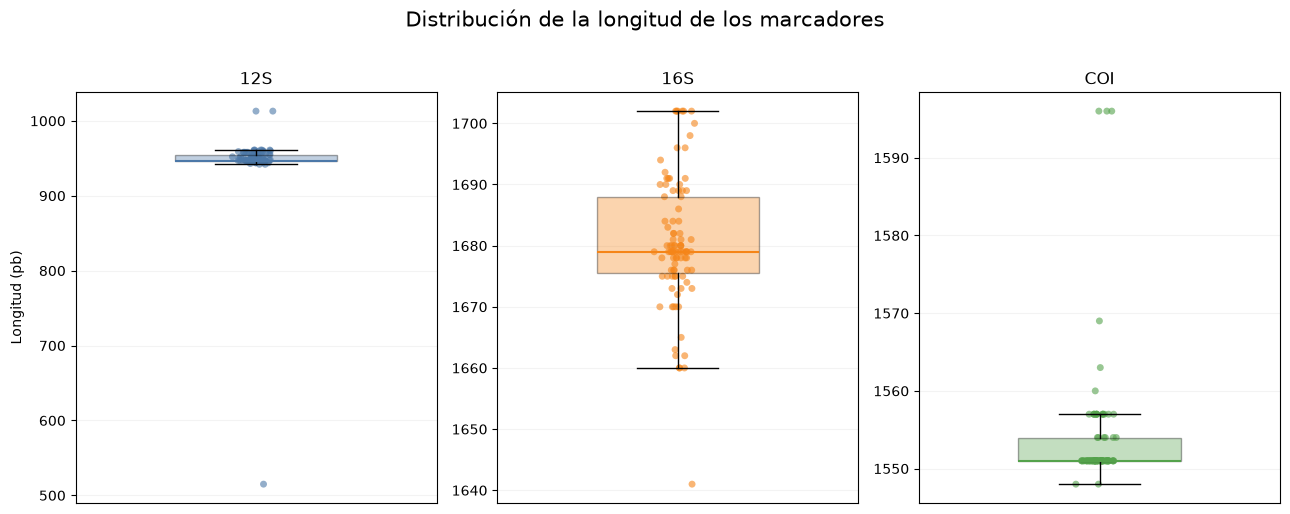

PNG: /home/matias-zabala/Descargas/Tesina/secuencias/Analisis/Figuras/seleccion_marcador/01_longitud/distribucion_longitud_marcadores.png
PDF: /home/matias-zabala/Descargas/Tesina/secuencias/Analisis/Figuras/seleccion_marcador/01_longitud/distribucion_longitud_marcadores.pdf


In [31]:
# =========================
# FIGURA: DISTRIBUCIÓN DE LONGITUD POR MARCADOR
# =========================

colores = {
    "12S": "#4C78A8",
    "16S": "#F58518",
    "COI": "#54A24B"
}

genes = ["12S", "16S", "COI"]

fig, axes = plt.subplots(
    1, 3,
    figsize=(13, 5)
)

for ax, gen in zip(axes, genes):

    # Todas las secuencias del marcador
    datos = secuencias.loc[
        secuencias["gen"] == gen,
        "longitud"
    ].dropna()

    # -------------------------
    # BOXPLOT
    # -------------------------

    bp = ax.boxplot(
        datos,
        positions=[1],
        widths=0.45,
        patch_artist=True,
        showfliers=False
    )

    for caja in bp["boxes"]:
        caja.set_facecolor(colores[gen])
        caja.set_alpha(0.35)

    for mediana in bp["medians"]:
        mediana.set_color(colores[gen])
        mediana.set_linewidth(1.5)

    # -------------------------
    # PUNTOS INDIVIDUALES
    # -------------------------

    np.random.seed(42)

    jitter = np.random.normal(
        1,
        0.025,
        size=len(datos)
    )

    ax.scatter(
        jitter,
        datos,
        color=colores[gen],
        alpha=0.60,
        s=25,
        edgecolors="none"
    )

    # -------------------------
    # FORMATO
    # -------------------------

    ax.set_title(
        gen,
        fontsize=12
    )

    ax.set_xticks([])

    ax.grid(
        axis="y",
        alpha=0.15
    )

    # Cada marcador conserva su propia escala Y
    ax.set_ylim(
        datos.min() - (datos.max() - datos.min()) * 0.05,
        datos.max() + (datos.max() - datos.min()) * 0.05
    )


axes[0].set_ylabel(
    "Longitud (pb)"
)

fig.suptitle(
    "Distribución de la longitud de los marcadores",
    fontsize=15,
    y=1.02
)

plt.tight_layout()


# =========================
# GUARDADO
# =========================

ruta_png = (
    FIGURAS
    / "01_longitud"
    / "distribucion_longitud_marcadores.png"
)

ruta_pdf = (
    FIGURAS
    / "01_longitud"
    / "distribucion_longitud_marcadores.pdf"
)

plt.savefig(
    ruta_png,
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    ruta_pdf,
    bbox_inches="tight"
)

plt.show()

print(f"PNG: {ruta_png}")
print(f"PDF: {ruta_pdf}")

# 3. Distancias genéticas

La divergencia genética entre secuencias se evaluó mediante la distancia p (*p-distance*), calculada como la proporción de sitios nucleotídicos diferentes respecto del total de posiciones comparables entre cada par de secuencias.

Se consideraron como sitios comparables únicamente aquellas posiciones en las que ambas secuencias presentaron nucleótidos A, T, G o C. Las posiciones correspondientes a gaps o caracteres ambiguos fueron excluidas de cada comparación.

El análisis se realizó por separado para los marcadores 12S, 16S y COI, considerando tres niveles de comparación:

1. variabilidad intraespecífica de las especies no nativas;
2. divergencia interespecífica entre especies no nativas;
3. divergencia entre especies no nativas y el conjunto de especies nativas de contraste.

In [32]:
# =========================
# FUNCIÓN DE P-DISTANCE
# =========================

def calcular_p_distance(seq1, seq2):
    
    validos = {"A", "T", "G", "C"}
    
    diferencias = 0
    sitios_comparados = 0
    
    for nt1, nt2 in zip(seq1, seq2):
        
        if nt1 in validos and nt2 in validos:
            
            sitios_comparados += 1
            
            if nt1 != nt2:
                diferencias += 1
    
    if sitios_comparados == 0:
        return np.nan
    
    return diferencias / sitios_comparados

In [33]:
# =========================
# CARGA DE ALINEAMIENTOS
# =========================

archivos_alineados = {
    "12S": ALINEAMIENTOS / "12S_alineado.fasta",
    "16S": ALINEAMIENTOS / "16S_alineado.fasta",
    "COI": ALINEAMIENTOS / "COI_alineado.fasta",
}

alineamientos = {}

for gen, archivo in archivos_alineados.items():
    
    if not archivo.exists():
        raise FileNotFoundError(
            f"No se encontró el alineamiento de {gen}: {archivo}"
        )
    
    registros = list(SeqIO.parse(archivo, "fasta"))
    alineamientos[gen] = registros
    
    longitudes = {len(reg.seq) for reg in registros}
    
    print(f"{gen}")
    print(f"  Secuencias: {len(registros)}")
    print(f"  Longitud(es) del alineamiento: {sorted(longitudes)}")
    print()

12S
  Secuencias: 95
  Longitud(es) del alineamiento: [1059]

16S
  Secuencias: 95
  Longitud(es) del alineamiento: [2246]

COI
  Secuencias: 95
  Longitud(es) del alineamiento: [2040]



In [34]:
# =========================
# IDENTIFICADORES DE LOS ALINEAMIENTOS
# =========================

for gen in ["12S", "16S", "COI"]:
    
    print(f"\n--- {gen} ---")
    
    for registro in alineamientos[gen][:10]:
        print(registro.id)


--- 12S ---
Acipenser_baerii|INV|AB1368|12S|69-1029
Acipenser_baerii|INV|F20-043|12S|69-1029
Acipenser_baerii|INV|F20-045|12S|69-1029
Acipenser_gueldenstaedtii|INV|Complete
Acipenser_gueldenstaedtii|INV|Dinoville|12S|69-1029
Huso_huso|INV|Complete
Huso_huso|INV|Complete
Coregonus_clupeaformis|INV|Complete
Coregonus_clupeaformis|INV|NEFCF17264|12S|69-1015
Coregonus_clupeaformis|INV|NEFCF17265|12S|69-1015

--- 16S ---
Acipenser_baerii|INV|AB1368|16S|1101-2802
Acipenser_baerii|INV|F20-043|16S|1101-2802
Acipenser_baerii|INV|F20-045|16S|1101-2802
Acipenser_gueldenstaedtii|INV|Complete
Acipenser_gueldenstaedtii|INV|Dinoville|16S|1101-2802
Huso_huso|INV|Complete
Huso_huso|INV|Complete
Coregonus_clupeaformis|INV|Complete
Coregonus_clupeaformis|INV|NEFCF17264|16S|1088-2766
Coregonus_clupeaformis|INV|NEFCF17265|16S|1088-2766

--- COI ---
Acipenser_baerii|INV|AB1368|COI|5508-7061
Acipenser_baerii|INV|F20-043|COI|5508-7061
Acipenser_baerii|INV|F20-045|COI|5508-7061
Acipenser_gueldenstaedtii|INV|C

In [35]:
# =========================
# METADATOS DE LOS ALINEAMIENTOS
# =========================

def extraer_metadatos_id(registro_id):
    
    partes = registro_id.split("|")
    
    especie = partes[0].replace("_", " ")
    tipo_original = partes[1]
    
    if tipo_original == "INV":
        tipo = "no_nativa"
    elif tipo_original in {"NAT", "nativa"}:
        tipo = "nativa"
    else:
        tipo = "desconocido"
    
    return especie, tipo


filas = []

for gen, registros in alineamientos.items():
    
    for registro in registros:
        
        especie, tipo = extraer_metadatos_id(registro.id)
        
        filas.append({
            "gen": gen,
            "id_fasta": registro.id,
            "especie": especie,
            "tipo": tipo
        })

metadatos_alineamientos = pd.DataFrame(filas)

control_metadatos = (
    metadatos_alineamientos
    .groupby(["gen", "tipo"])
    .size()
    .unstack(fill_value=0)
)

display(control_metadatos)

print(
    "\nEspecies distintas:",
    metadatos_alineamientos["especie"].nunique()
)

tipo,nativa,no_nativa
gen,,
12S,10,85
16S,10,85
COI,10,85



Especies distintas: 43


In [36]:
# =========================
# FUNCIÓN DE P-DISTANCE
# =========================

def calcular_p_distance(seq1, seq2):
    
    validos = {"A", "T", "G", "C"}
    
    diferencias = 0
    sitios_comparados = 0
    
    for nt1, nt2 in zip(seq1, seq2):
        
        nt1 = nt1.upper()
        nt2 = nt2.upper()
        
        if nt1 in validos and nt2 in validos:
            
            sitios_comparados += 1
            
            if nt1 != nt2:
                diferencias += 1
    
    if sitios_comparados == 0:
        return np.nan, 0
    
    p_distance = diferencias / sitios_comparados
    
    return p_distance, sitios_comparados

In [37]:
# =========================
# P-DISTANCE INTRAESPECÍFICA
# =========================

resultados_intra = []

for gen, registros in alineamientos.items():
    
    # Agrupar secuencias no nativas por especie
    por_especie = {}
    
    for registro in registros:
        
        especie, tipo = extraer_metadatos_id(registro.id)
        
        if tipo != "no_nativa":
            continue
        
        por_especie.setdefault(especie, []).append(registro)
    
    # Comparaciones dentro de cada especie
    for especie, secuencias_especie in por_especie.items():
        
        for seq1, seq2 in combinations(secuencias_especie, 2):
            
            distancia, sitios = calcular_p_distance(
                str(seq1.seq),
                str(seq2.seq)
            )
            
            resultados_intra.append({
                "gen": gen,
                "especie": especie,
                "id_1": seq1.id,
                "id_2": seq2.id,
                "p_distance": distancia,
                "sitios_comparados": sitios
            })

distancias_intra = pd.DataFrame(resultados_intra)

print(f"Comparaciones intraespecíficas totales: {len(distancias_intra)}")

display(distancias_intra.head(10))

Comparaciones intraespecíficas totales: 219


,gen,especie,id_1,id_2,p_distance,sitios_comparados
0,12S,Acipenser baerii,Acipenser_baerii|INV|AB1368|12S|69-1029,Acipenser_baerii|INV|F20-043|12S|69-1029,0.000000,961
1,12S,Acipenser baerii,Acipenser_baerii|INV|AB1368|12S|69-1029,Acipenser_baerii|INV|F20-045|12S|69-1029,0.000000,961
2,12S,Acipenser baerii,Acipenser_baerii|INV|F20-043|12S|69-1029,Acipenser_baerii|INV|F20-045|12S|69-1029,0.000000,961
3,12S,Acipenser gueldenstaedtii,Acipenser_gueldenstaedtii|INV|Complete,Acipenser_gueldenstaedtii|INV|Dinoville|12S|69...,0.000000,961
4,12S,Huso huso,Huso_huso|INV|Complete,Huso_huso|INV|Complete,0.000000,1013
5,12S,Coregonus clupeaformis,Coregonus_clupeaformis|INV|Complete,Coregonus_clupeaformis|INV|NEFCF17264|12S|69-1015,0.003168,947
6,12S,Coregonus clupeaformis,Coregonus_clupeaformis|INV|Complete,Coregonus_clupeaformis|INV|NEFCF17265|12S|69-1015,0.003168,947
7,12S,Coregonus clupeaformis,Coregonus_clupeaformis|INV|NEFCF17264|12S|69-1015,Coregonus_clupeaformis|INV|NEFCF17265|12S|69-1015,0.000000,947
8,12S,Oncorhynchus gorbuscha,Oncorhynchus_gorbuscha|INV|Complete,Oncorhynchus_gorbuscha|INV|MNHN-IC-2022-0168|1...,0.001056,947
9,12S,Oncorhynchus kisutch,Oncorhynchus_kisutch|INV|FB4|12S|69-1015,Oncorhynchus_kisutch|INV|NEFC_F16-295|12S|69-1015,0.000000,947


In [38]:
# =========================
# RESUMEN INTRAESPECÍFICO POR ESPECIE
# =========================

resumen_intra_especie = (
    distancias_intra
    .groupby(["gen", "especie"])
    .agg(
        n_comparaciones=("p_distance", "count"),
        p_intra_media=("p_distance", "mean"),
        p_intra_mediana=("p_distance", "median"),
        p_intra_max=("p_distance", "max"),
        sitios_min=("sitios_comparados", "min"),
        sitios_max=("sitios_comparados", "max")
    )
    .reset_index()
)

resumen_intra_especie["gen"] = pd.Categorical(
    resumen_intra_especie["gen"],
    categories=["12S", "16S", "COI"],
    ordered=True
)

resumen_intra_especie = (
    resumen_intra_especie
    .sort_values(["gen", "especie"])
    .reset_index(drop=True)
)

display(resumen_intra_especie.head(15).round(6))

,gen,especie,n_comparaciones,p_intra_media,p_intra_mediana,p_intra_max,sitios_min,sitios_max
0,12S,Acipenser baerii,3,0.000000,0.000000,0.000000,961,961
1,12S,Acipenser gueldenstaedtii,1,0.000000,0.000000,0.000000,961,961
2,12S,Ameiurus nebulosus,3,0.003472,0.005208,0.005208,960,960
3,12S,Carassius auratus,3,0.000000,0.000000,0.000000,952,954
4,12S,Coregonus clupeaformis,3,0.002112,0.003168,0.003168,947,947
5,12S,Ctenopharyngodon idella,1,0.002088,0.002088,0.002088,958,958
6,12S,Cyprinus Carpio,3,0.000000,0.000000,0.000000,955,955
7,12S,Danio Rerio,3,0.000000,0.000000,0.000000,952,952
8,12S,Gambusia affinis,1,0.000000,0.000000,0.000000,947,947
9,12S,Gambusia holbrooki,1,0.000000,0.000000,0.000000,948,948


In [39]:
# =========================
# RESUMEN INTRAESPECÍFICO POR MARCADOR
# =========================

resumen_intra_marcador = (
    resumen_intra_especie
    .groupby("gen", observed=True)
    .agg(
        n_especies=("especie", "nunique"),
        media_p_intra=("p_intra_media", "mean"),
        mediana_p_intra=("p_intra_media", "median"),
        desvio_p_intra=("p_intra_media", "std"),
        minimo_p_intra=("p_intra_media", "min"),
        maximo_p_intra=("p_intra_media", "max")
    )
    .reset_index()
)

display(resumen_intra_marcador.round(6))

,gen,n_especies,media_p_intra,mediana_p_intra,desvio_p_intra,minimo_p_intra,maximo_p_intra
0,12S,31,0.002686,0.000696,0.006997,0.0,0.035386
1,16S,31,0.004223,0.000596,0.011506,0.0,0.058792
2,COI,31,0.008234,0.001927,0.022339,0.0,0.114965


In [40]:
# =========================
# P-DISTANCE INTERESPECÍFICA
# ENTRE ESPECIES NO NATIVAS
# =========================

resultados_inter_no_nativas = []

for gen, registros in alineamientos.items():
    
    # Mantener únicamente especies no nativas
    registros_inv = []
    
    for registro in registros:
        
        especie, tipo = extraer_metadatos_id(registro.id)
        
        if tipo == "no_nativa":
            registros_inv.append((registro, especie))
    
    # Comparar todos los pares de secuencias
    for (seq1, especie1), (seq2, especie2) in combinations(registros_inv, 2):
        
        # Solo especies diferentes
        if especie1 == especie2:
            continue
        
        distancia, sitios = calcular_p_distance(
            str(seq1.seq),
            str(seq2.seq)
        )
        
        resultados_inter_no_nativas.append({
            "gen": gen,
            "especie_1": especie1,
            "especie_2": especie2,
            "id_1": seq1.id,
            "id_2": seq2.id,
            "p_distance": distancia,
            "sitios_comparados": sitios
        })

distancias_inter_no_nativas = pd.DataFrame(
    resultados_inter_no_nativas
)

print(
    "Comparaciones interespecíficas entre secuencias no nativas:",
    len(distancias_inter_no_nativas)
)

display(distancias_inter_no_nativas.head(10))

Comparaciones interespecíficas entre secuencias no nativas: 10491


,gen,especie_1,especie_2,id_1,id_2,p_distance,sitios_comparados
0,12S,Acipenser baerii,Acipenser gueldenstaedtii,Acipenser_baerii|INV|AB1368|12S|69-1029,Acipenser_gueldenstaedtii|INV|Complete,0.001041,961
1,12S,Acipenser baerii,Acipenser gueldenstaedtii,Acipenser_baerii|INV|AB1368|12S|69-1029,Acipenser_gueldenstaedtii|INV|Dinoville|12S|69...,0.001041,961
2,12S,Acipenser baerii,Huso huso,Acipenser_baerii|INV|AB1368|12S|69-1029,Huso_huso|INV|Complete,0.013528,961
3,12S,Acipenser baerii,Huso huso,Acipenser_baerii|INV|AB1368|12S|69-1029,Huso_huso|INV|Complete,0.013528,961
4,12S,Acipenser baerii,Coregonus clupeaformis,Acipenser_baerii|INV|AB1368|12S|69-1029,Coregonus_clupeaformis|INV|Complete,0.169312,945
5,12S,Acipenser baerii,Coregonus clupeaformis,Acipenser_baerii|INV|AB1368|12S|69-1029,Coregonus_clupeaformis|INV|NEFCF17264|12S|69-1015,0.166138,945
6,12S,Acipenser baerii,Coregonus clupeaformis,Acipenser_baerii|INV|AB1368|12S|69-1029,Coregonus_clupeaformis|INV|NEFCF17265|12S|69-1015,0.166138,945
7,12S,Acipenser baerii,Oncorhynchus gorbuscha,Acipenser_baerii|INV|AB1368|12S|69-1029,Oncorhynchus_gorbuscha|INV|Complete,0.178836,945
8,12S,Acipenser baerii,Oncorhynchus gorbuscha,Acipenser_baerii|INV|AB1368|12S|69-1029,Oncorhynchus_gorbuscha|INV|MNHN-IC-2022-0168|1...,0.179894,945
9,12S,Acipenser baerii,Oncorhynchus kisutch,Acipenser_baerii|INV|AB1368|12S|69-1029,Oncorhynchus_kisutch|INV|FB4|12S|69-1015,0.177778,945


In [41]:
# =========================
# NORMALIZACIÓN Y RESUMEN POR PAREJA DE ESPECIES
# =========================

# Copia para no modificar las comparaciones crudas
inter_normalizado = distancias_inter_no_nativas.copy()

# Ordenar alfabéticamente las especies de cada comparación
pares_ordenados = inter_normalizado.apply(
    lambda fila: sorted([
        fila["especie_1"],
        fila["especie_2"]
    ]),
    axis=1
)

inter_normalizado["especie_A"] = [
    par[0] for par in pares_ordenados
]

inter_normalizado["especie_B"] = [
    par[1] for par in pares_ordenados
]

# Resumir ahora sí por pareja única de especies
resumen_inter_pares = (
    inter_normalizado
    .groupby(["gen", "especie_A", "especie_B"])
    .agg(
        n_comparaciones=("p_distance", "count"),
        p_inter_media=("p_distance", "mean"),
        p_inter_mediana=("p_distance", "median"),
        p_inter_min=("p_distance", "min"),
        p_inter_max=("p_distance", "max"),
        sitios_min=("sitios_comparados", "min"),
        sitios_max=("sitios_comparados", "max")
    )
    .reset_index()
)

resumen_inter_pares["gen"] = pd.Categorical(
    resumen_inter_pares["gen"],
    categories=["12S", "16S", "COI"],
    ordered=True
)

resumen_inter_pares = (
    resumen_inter_pares
    .sort_values(["gen", "p_inter_media"])
    .reset_index(drop=True)
)

print(
    "Pares de especies evaluados:",
    len(resumen_inter_pares)
)

print("\nPares por marcador:")
display(
    resumen_inter_pares
    .groupby("gen", observed=True)
    .size()
    .rename("n_pares")
    .to_frame()
)

display(resumen_inter_pares.head(15).round(6))

Pares de especies evaluados: 1584

Pares por marcador:


,n_pares
gen,
12S,528
16S,528
COI,528


,gen,especie_A,especie_B,n_comparaciones,p_inter_media,p_inter_mediana,p_inter_min,p_inter_max,sitios_min,sitios_max
0,12S,Acipenser baerii,Acipenser gueldenstaedtii,6,0.001041,0.001041,0.001041,0.001041,961,961
1,12S,Salvelinus alpinus,Salvelinus namaycush,9,0.004928,0.005280,0.004224,0.005280,947,947
2,12S,Gambusia affinis,Gambusia holbrooki,4,0.005280,0.005280,0.005280,0.005280,947,947
3,12S,Hypophthalmichthys molitrix,Hypophthalmichthys nobilis,9,0.007697,0.007307,0.006270,0.009524,944,959
4,12S,Salvelinus fontinalis,Salvelinus namaycush,9,0.007744,0.007392,0.007392,0.008448,947,947
5,12S,Salvelinus alpinus,Salvelinus fontinalis,9,0.010560,0.010560,0.009504,0.011616,947,947
6,12S,Oncorhynchus kisutch,Oncorhynchus tshawytscha,6,0.011616,0.011616,0.011616,0.011616,947,947
7,12S,Acipenser gueldenstaedtii,Huso huso,4,0.012487,0.012487,0.012487,0.012487,961,961
8,12S,Acipenser baerii,Huso huso,6,0.013528,0.013528,0.013528,0.013528,961,961
9,12S,Oncorhynchus mykiss,Oncorhynchus nerka,9,0.013728,0.013728,0.013728,0.013728,947,947


In [42]:
# =========================
# RESUMEN INTERESPECÍFICO POR MARCADOR
# =========================

resumen_inter_marcador = (
    resumen_inter_pares
    .groupby("gen", observed=True)
    .agg(
        n_pares_especies=("p_inter_media", "count"),
        media_p_inter=("p_inter_media", "mean"),
        mediana_p_inter=("p_inter_media", "median"),
        desvio_p_inter=("p_inter_media", "std"),
        minimo_p_inter=("p_inter_min", "min"),
        maximo_p_inter=("p_inter_max", "max")
    )
    .reset_index()
)

display(
    resumen_inter_marcador.round(6)
)

,gen,n_pares_especies,media_p_inter,mediana_p_inter,desvio_p_inter,minimo_p_inter,maximo_p_inter
0,12S,528,0.166857,0.183969,0.061573,0.001041,0.261981
1,16S,528,0.200809,0.227124,0.074986,0.005288,0.290909
2,COI,528,0.190434,0.204313,0.040747,0.009009,0.234687


In [43]:
# =========================
# P-DISTANCE
# NO NATIVAS VS NATIVAS
# =========================

resultados_contraste_nativas = []

for gen, registros in alineamientos.items():

    no_nativas = []
    nativas = []

    for registro in registros:

        especie, tipo = extraer_metadatos_id(registro.id)

        if tipo == "no_nativa":
            no_nativas.append((registro, especie))

        elif tipo == "nativa":
            nativas.append((registro, especie))

    # Comparar cada secuencia no nativa
    # contra cada secuencia nativa
    for seq_inv, especie_inv in no_nativas:

        for seq_nat, especie_nat in nativas:

            distancia, sitios = calcular_p_distance(
                str(seq_inv.seq),
                str(seq_nat.seq)
            )

            resultados_contraste_nativas.append({
                "gen": gen,
                "especie_no_nativa": especie_inv,
                "especie_nativa": especie_nat,
                "id_no_nativa": seq_inv.id,
                "id_nativa": seq_nat.id,
                "p_distance": distancia,
                "sitios_comparados": sitios
            })

distancias_contraste_nativas = pd.DataFrame(
    resultados_contraste_nativas
)

print(
    "Comparaciones no nativa-nativa:",
    len(distancias_contraste_nativas)
)

display(
    distancias_contraste_nativas.head(10)
)

Comparaciones no nativa-nativa: 2550


,gen,especie_no_nativa,especie_nativa,id_no_nativa,id_nativa,p_distance,sitios_comparados
0,12S,Acipenser baerii,Cichlasoma dimerus,Acipenser_baerii|INV|AB1368|12S|69-1029,Cichlasoma_dimerus|NAT|Complete,0.218684,942
1,12S,Acipenser baerii,Pimelodus maculatus,Acipenser_baerii|INV|AB1368|12S|69-1029,Pimelodus_maculatus|NAT|Complete,0.174788,944
2,12S,Acipenser baerii,Pseudoplatystoma corruscans,Acipenser_baerii|INV|AB1368|12S|69-1029,Pseudoplatystoma_corruscans|NAT|Complete,0.196881,513
3,12S,Acipenser baerii,Astyanax lacustris,Acipenser_baerii|INV|AB1368|12S|69-1029,Astyanax_lacustris|NAT|Voucher,0.195096,938
4,12S,Acipenser baerii,Brycon orbignyanus,Acipenser_baerii|INV|AB1368|12S|69-1029,Brycon_orbignyanus|NAT|Complete,0.194268,942
5,12S,Acipenser baerii,Salminus brasiliensis,Acipenser_baerii|INV|AB1368|12S|69-1029,Salminus_brasiliensis|NAT|Complete,0.190021,942
6,12S,Acipenser baerii,Piaractus mesopotamicus,Acipenser_baerii|INV|AB1368|12S|69-1029,Piaractus_mesopotamicus|NAT|Complete,0.199789,946
7,12S,Acipenser baerii,Prochilodus lineatus,Acipenser_baerii|INV|AB1368|12S|69-1029,Prochilodus_lineatus|NAT|Complete,0.195975,944
8,12S,Acipenser baerii,Hoplias malabaricus,Acipenser_baerii|INV|AB1368|12S|69-1029,Hoplias_malabaricus|NAT|Complete,0.204255,940
9,12S,Acipenser baerii,Leporinus obtusidens,Acipenser_baerii|INV|AB1368|12S|69-1029,Leporinus_obtusidens|NAT|Complete,0.204473,939


In [44]:
# =========================
# RESUMEN POR PAREJA DE ESPECIES
# NO NATIVA VS NATIVA
# =========================

resumen_contraste_pares = (
    distancias_contraste_nativas
    .groupby(
        ["gen", "especie_no_nativa", "especie_nativa"]
    )
    .agg(
        n_comparaciones=("p_distance", "count"),
        p_contraste_media=("p_distance", "mean"),
        p_contraste_mediana=("p_distance", "median"),
        p_contraste_min=("p_distance", "min"),
        p_contraste_max=("p_distance", "max"),
        sitios_min=("sitios_comparados", "min"),
        sitios_max=("sitios_comparados", "max")
    )
    .reset_index()
)

resumen_contraste_pares["gen"] = pd.Categorical(
    resumen_contraste_pares["gen"],
    categories=["12S", "16S", "COI"],
    ordered=True
)

resumen_contraste_pares = (
    resumen_contraste_pares
    .sort_values(["gen", "p_contraste_media"])
    .reset_index(drop=True)
)

print(
    "Pares no nativa-nativa evaluados:",
    len(resumen_contraste_pares)
)

print("\nPares por marcador:")

display(
    resumen_contraste_pares
    .groupby("gen", observed=True)
    .size()
    .rename("n_pares")
    .to_frame()
)

display(
    resumen_contraste_pares.head(15).round(6)
)

Pares no nativa-nativa evaluados: 990

Pares por marcador:


,n_pares
gen,
12S,330
16S,330
COI,330


,gen,especie_no_nativa,especie_nativa,n_comparaciones,p_contraste_media,p_contraste_mediana,p_contraste_min,p_contraste_max,sitios_min,sitios_max
0,12S,Ictalurus punctatus,Pimelodus maculatus,3,0.085181,0.084477,0.084477,0.086589,947,947
1,12S,Clarias gariepinus,Pseudoplatystoma corruscans,1,0.085938,0.085938,0.085938,0.085938,512,512
2,12S,Rocío octofasciata,Cichlasoma dimerus,1,0.090042,0.090042,0.090042,0.090042,944,944
3,12S,Ameiurus nebulosus,Pseudoplatystoma corruscans,3,0.091146,0.091797,0.089844,0.091797,512,512
4,12S,Ictalurus punctatus,Pseudoplatystoma corruscans,3,0.093281,0.093933,0.091977,0.093933,511,511
5,12S,Clarias gariepinus,Pimelodus maculatus,1,0.094837,0.094837,0.094837,0.094837,949,949
6,12S,Ameiurus nebulosus,Pimelodus maculatus,3,0.097853,0.098205,0.097149,0.098205,947,947
7,12S,Oreochromis niloticus,Cichlasoma dimerus,3,0.118188,0.118896,0.116773,0.118896,942,942
8,12S,Clarias gariepinus,Prochilodus lineatus,1,0.133616,0.133616,0.133616,0.133616,943,943
9,12S,Clarias gariepinus,Piaractus mesopotamicus,1,0.136653,0.136653,0.136653,0.136653,944,944


In [45]:
# =========================
# RESUMEN NO NATIVA-NATIVA
# POR MARCADOR
# =========================

resumen_contraste_marcador = (
    resumen_contraste_pares
    .groupby("gen", observed=True)
    .agg(
        n_pares_especies=("p_contraste_media", "count"),
        media_p_contraste=("p_contraste_media", "mean"),
        mediana_p_contraste=("p_contraste_media", "median"),
        desvio_p_contraste=("p_contraste_media", "std"),
        minimo_p_contraste=("p_contraste_min", "min"),
        maximo_p_contraste=("p_contraste_max", "max")
    )
    .reset_index()
)

display(
    resumen_contraste_marcador.round(6)
)

,gen,n_pares_especies,media_p_contraste,mediana_p_contraste,desvio_p_contraste,minimo_p_contraste,maximo_p_contraste
0,12S,330,0.188277,0.184812,0.027987,0.084477,0.255839
1,16S,330,0.228014,0.230321,0.033522,0.111111,0.295136
2,COI,330,0.201457,0.201094,0.013962,0.139265,0.231464


In [46]:
# =========================
# GUARDADO DE RESULTADOS
# DISTANCIAS GENÉTICAS
# =========================

CARPETA_DISTANCIAS = RESULTADOS / "02_distancias"

# Intraespecíficas
distancias_intra.to_csv(
    CARPETA_DISTANCIAS / "distancias_intra_pares_secuencias.csv",
    index=False
)

resumen_intra_especie.to_csv(
    CARPETA_DISTANCIAS / "resumen_intra_por_especie.csv",
    index=False
)

resumen_intra_marcador.to_csv(
    CARPETA_DISTANCIAS / "resumen_intra_por_marcador.csv",
    index=False
)

# Interespecíficas entre especies no nativas
distancias_inter_no_nativas.to_csv(
    CARPETA_DISTANCIAS / "distancias_inter_no_nativas_pares_secuencias.csv",
    index=False
)

resumen_inter_pares.to_csv(
    CARPETA_DISTANCIAS / "resumen_inter_no_nativas_por_par_especies.csv",
    index=False
)

resumen_inter_marcador.to_csv(
    CARPETA_DISTANCIAS / "resumen_inter_no_nativas_por_marcador.csv",
    index=False
)

# Contraste no nativas vs nativas
distancias_contraste_nativas.to_csv(
    CARPETA_DISTANCIAS / "distancias_no_nativa_nativa_pares_secuencias.csv",
    index=False
)

resumen_contraste_pares.to_csv(
    CARPETA_DISTANCIAS / "resumen_no_nativa_nativa_por_par_especies.csv",
    index=False
)

resumen_contraste_marcador.to_csv(
    CARPETA_DISTANCIAS / "resumen_no_nativa_nativa_por_marcador.csv",
    index=False
)

print("Resultados guardados en:")
print(CARPETA_DISTANCIAS)


Resultados guardados en:
/home/matias-zabala/Descargas/Tesina/secuencias/Analisis/Resultados/seleccion_marcador/02_distancias


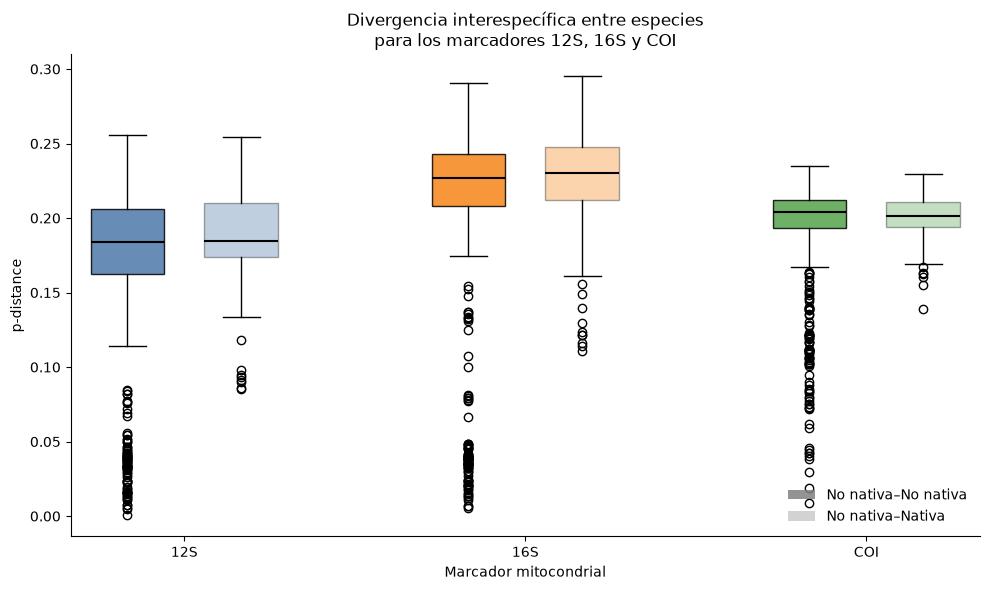

Figura guardada en:
/home/matias-zabala/Descargas/Tesina/secuencias/Analisis/Figuras/seleccion_marcador/02_distancias/divergencia_interespecifica.png
/home/matias-zabala/Descargas/Tesina/secuencias/Analisis/Figuras/seleccion_marcador/02_distancias/divergencia_interespecifica.pdf


In [47]:
# =========================
# FIGURA
# DIVERGENCIA INTERESPECÍFICA
# =========================

datos_inter_fig = []

# No nativa vs no nativa
for _, fila in resumen_inter_pares.iterrows():
    datos_inter_fig.append({
        "gen": str(fila["gen"]),
        "comparacion": "No nativa–No nativa",
        "p_distance": fila["p_inter_media"]
    })

# No nativa vs nativa
for _, fila in resumen_contraste_pares.iterrows():
    datos_inter_fig.append({
        "gen": str(fila["gen"]),
        "comparacion": "No nativa–Nativa",
        "p_distance": fila["p_contraste_media"]
    })

datos_inter_fig = pd.DataFrame(datos_inter_fig)

marcadores = ["12S", "16S", "COI"]
colores = {
    "12S": "#4C78A8",
    "16S": "#F58518",
    "COI": "#54A24B"
}

fig, ax = plt.subplots(figsize=(10, 6))

posiciones = []
datos_boxplot = []
colores_boxplot = []

for i, gen in enumerate(marcadores):

    # Inter no nativa-no nativa
    valores_nn = datos_inter_fig[
        (datos_inter_fig["gen"] == gen) &
        (datos_inter_fig["comparacion"] == "No nativa–No nativa")
    ]["p_distance"].dropna()

    # Contraste no nativa-nativa
    valores_nat = datos_inter_fig[
        (datos_inter_fig["gen"] == gen) &
        (datos_inter_fig["comparacion"] == "No nativa–Nativa")
    ]["p_distance"].dropna()

    posiciones.extend([i * 3 + 1, i * 3 + 2])
    datos_boxplot.extend([valores_nn, valores_nat])
    colores_boxplot.extend([colores[gen], colores[gen]])

bp = ax.boxplot(
    datos_boxplot,
    positions=posiciones,
    widths=0.65,
    patch_artist=True,
    showfliers=True,
    medianprops={"color": "black", "linewidth": 1.5}
)

# Mismo color para cada marcador;
# distinta transparencia para cada tipo de comparación
for i, caja in enumerate(bp["boxes"]):
    caja.set_facecolor(colores_boxplot[i])

    if i % 2 == 0:
        caja.set_alpha(0.85)   # no nativa-no nativa
    else:
        caja.set_alpha(0.35)   # no nativa-nativa

ax.set_xticks(
    [1.5, 4.5, 7.5],
    ["12S", "16S", "COI"]
)

ax.set_ylabel("p-distance")
ax.set_xlabel("Marcador mitocondrial")

ax.set_title(
    "Divergencia interespecífica entre especies\n"
    "para los marcadores 12S, 16S y COI"
)

# Leyenda manual
from matplotlib.patches import Patch

leyenda = [
    Patch(
        facecolor="gray",
        alpha=0.85,
        label="No nativa–No nativa"
    ),
    Patch(
        facecolor="gray",
        alpha=0.35,
        label="No nativa–Nativa"
    )
]

ax.legend(
    handles=leyenda,
    frameon=False,
    loc="lower right"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

# Guardado
ruta_png = (
    FIGURAS /
    "02_distancias" /
    "divergencia_interespecifica.png"
)

ruta_pdf = (
    FIGURAS /
    "02_distancias" /
    "divergencia_interespecifica.pdf"
)

plt.savefig(
    ruta_png,
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    ruta_pdf,
    bbox_inches="tight"
)

plt.show()

print("Figura guardada en:")
print(ruta_png)
print(ruta_pdf)

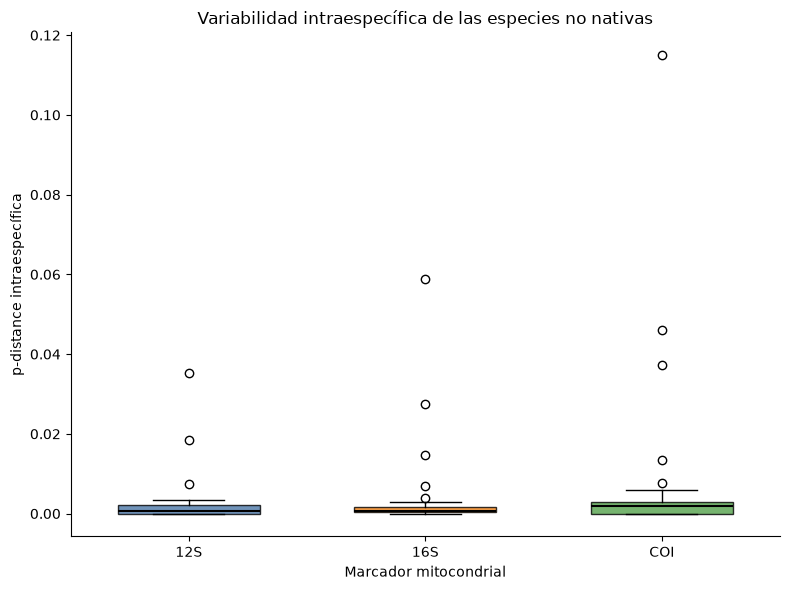

Figura guardada en:
/home/matias-zabala/Descargas/Tesina/secuencias/Analisis/Figuras/seleccion_marcador/02_distancias/variabilidad_intraespecifica.png
/home/matias-zabala/Descargas/Tesina/secuencias/Analisis/Figuras/seleccion_marcador/02_distancias/variabilidad_intraespecifica.pdf


In [48]:
# =========================
# FIGURA
# VARIABILIDAD INTRAESPECÍFICA
# =========================

marcadores = ["12S", "16S", "COI"]

colores = {
    "12S": "#4C78A8",
    "16S": "#F58518",
    "COI": "#54A24B"
}

datos_boxplot = []
posiciones = [1, 2, 3]

for gen in marcadores:

    valores = resumen_intra_especie[
        resumen_intra_especie["gen"] == gen
    ]["p_intra_media"].dropna()

    datos_boxplot.append(valores)


fig, ax = plt.subplots(figsize=(8, 6))

bp = ax.boxplot(
    datos_boxplot,
    positions=posiciones,
    widths=0.6,
    patch_artist=True,
    showfliers=True,
    medianprops={
        "color": "black",
        "linewidth": 1.5
    }
)

# Colores por marcador
for caja, gen in zip(bp["boxes"], marcadores):
    caja.set_facecolor(colores[gen])
    caja.set_alpha(0.8)


ax.set_xticks(
    posiciones,
    marcadores
)

ax.set_xlabel("Marcador mitocondrial")
ax.set_ylabel("p-distance intraespecífica")

ax.set_title(
    "Variabilidad intraespecífica de las especies no nativas"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()


# =========================
# GUARDADO
# =========================

ruta_png = (
    FIGURAS /
    "02_distancias" /
    "variabilidad_intraespecifica.png"
)

ruta_pdf = (
    FIGURAS /
    "02_distancias" /
    "variabilidad_intraespecifica.pdf"
)

plt.savefig(
    ruta_png,
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    ruta_pdf,
    bbox_inches="tight"
)

plt.show()

print("Figura guardada en:")
print(ruta_png)
print(ruta_pdf)

# 4. Resolución taxonómica

La resolución taxonómica de los marcadores 12S, 16S y COI se evaluó mediante el agrupamiento de las secuencias en árboles de distancia.

Se incluyeron tanto las especies no nativas como las especies nativas de contraste. Para las especies representadas por dos o más secuencias se evaluó si sus secuencias formaron grupos exclusivos, sin inclusión de secuencias pertenecientes a otras especies.

Las especies representadas por una única secuencia se mantuvieron en los árboles, pero no fueron consideradas evaluables para el análisis de agrupamiento a nivel intraespecífico.

In [49]:
# =========================
# HERRAMIENTAS PARA ÁRBOLES
# NEIGHBOR-JOINING
# =========================

from Bio.Phylo.TreeConstruction import DistanceMatrix, DistanceTreeConstructor
from Bio import Phylo

In [50]:
# =========================
# MATRIZ DE P-DISTANCE
# =========================

def construir_matriz_distancias(registros):
    
    nombres = [
        f"S{i:03d}"
        for i in range(len(registros))
    ]
    
    matriz = []
    
    for i in range(len(registros)):
        
        fila = []
        
        for j in range(i + 1):
            
            if i == j:
                distancia = 0.0
            
            else:
                distancia, _ = calcular_p_distance(
                    str(registros[i].seq),
                    str(registros[j].seq)
                )
            
            fila.append(distancia)
        
        matriz.append(fila)
    
    return DistanceMatrix(
        names=nombres,
        matrix=matriz
    )

In [51]:
# =========================
# CONSTRUCCIÓN DE ÁRBOLES
# NEIGHBOR-JOINING
# =========================

constructor = DistanceTreeConstructor()

arboles_nj = {}
mapas_secuencias = {}

for gen, registros in alineamientos.items():

    # Construir matriz de p-distance
    matriz = construir_matriz_distancias(registros)

    # Construir árbol Neighbor-Joining
    arbol = constructor.nj(matriz)

    # Mapa entre identificador interno y secuencia original
    mapa = {}

    for i, registro in enumerate(registros):

        codigo = f"S{i:03d}"

        especie, tipo = extraer_metadatos_id(registro.id)

        mapa[codigo] = {
            "especie": especie,
            "tipo": tipo,
            "id_original": registro.id
        }

    arboles_nj[gen] = arbol
    mapas_secuencias[gen] = mapa

    print(
        f"{gen}: "
        f"{len(registros)} secuencias | "
        f"{len(arbol.get_terminals())} terminales"
    )

12S: 95 secuencias | 95 terminales
16S: 95 secuencias | 95 terminales
COI: 95 secuencias | 95 terminales


In [52]:
# =========================
# EVALUACIÓN DE AGRUPAMIENTO
# EXCLUSIVO POR ESPECIE
# =========================

def evaluar_agrupamiento_exclusivo(arbol, mapa):

    resultados = []

    # Especies no nativas presentes en el árbol
    especies_no_nativas = sorted({
        datos["especie"]
        for datos in mapa.values()
        if datos["tipo"] == "no_nativa"
    })

    for especie in especies_no_nativas:

        # Terminales correspondientes a la especie
        terminales_especie = [
            terminal
            for terminal in arbol.get_terminals()
            if mapa[terminal.name]["especie"] == especie
        ]

        n_secuencias = len(terminales_especie)

        # Con una sola secuencia no puede evaluarse
        if n_secuencias < 2:

            resultados.append({
                "especie": especie,
                "n_secuencias": n_secuencias,
                "evaluable": False,
                "grupo_exclusivo": np.nan,
                "n_terminales_clado": np.nan,
                "especies_intrusas": None
            })

            continue

        # Ancestro común más reciente
        ancestro = arbol.common_ancestor(terminales_especie)

        terminales_clado = ancestro.get_terminals()

        especies_clado = {
            mapa[terminal.name]["especie"]
            for terminal in terminales_clado
        }

        especies_intrusas = sorted(
            especies_clado - {especie}
        )

        exclusivo = len(especies_intrusas) == 0

        resultados.append({
            "especie": especie,
            "n_secuencias": n_secuencias,
            "evaluable": True,
            "grupo_exclusivo": exclusivo,
            "n_terminales_clado": len(terminales_clado),
            "especies_intrusas": "; ".join(especies_intrusas)
            if especies_intrusas else ""
        })

    return pd.DataFrame(resultados)

In [53]:
# =========================
# RESOLUCIÓN TAXONÓMICA
# POR MARCADOR
# =========================

resultados_agrupamiento = []

for gen, arbol in arboles_nj.items():

    resultado = evaluar_agrupamiento_exclusivo(
        arbol,
        mapas_secuencias[gen]
    )

    resultado.insert(0, "gen", gen)

    resultados_agrupamiento.append(resultado)


resolucion_taxonomica = pd.concat(
    resultados_agrupamiento,
    ignore_index=True
)


# Orden de los marcadores
resolucion_taxonomica["gen"] = pd.Categorical(
    resolucion_taxonomica["gen"],
    categories=["12S", "16S", "COI"],
    ordered=True
)

resolucion_taxonomica = (
    resolucion_taxonomica
    .sort_values(["gen", "especie"])
    .reset_index(drop=True)
)


# =========================
# RESUMEN POR MARCADOR
# =========================

evaluables = resolucion_taxonomica[
    resolucion_taxonomica["evaluable"]
].copy()

resumen_resolucion = (
    evaluables
    .groupby("gen", observed=True)
    .agg(
        especies_evaluables=("especie", "count"),
        especies_exclusivas=("grupo_exclusivo", "sum")
    )
    .reset_index()
)

resumen_resolucion["porcentaje_exclusivas"] = (
    resumen_resolucion["especies_exclusivas"]
    / resumen_resolucion["especies_evaluables"]
    * 100
)


display(resumen_resolucion.round(2))

,gen,especies_evaluables,especies_exclusivas,porcentaje_exclusivas
0,12S,31,31,100.0
1,16S,31,29,93.548387
2,COI,31,31,100.0


In [54]:
# =========================
# ESPECIES NO RECUPERADAS
# COMO GRUPOS EXCLUSIVOS
# =========================

no_exclusivas = resolucion_taxonomica[
    (resolucion_taxonomica["evaluable"]) &
    (~resolucion_taxonomica["grupo_exclusivo"].astype(bool))
][
    [
        "gen",
        "especie",
        "n_secuencias",
        "n_terminales_clado",
        "especies_intrusas"
    ]
]

display(no_exclusivas)

,gen,especie,n_secuencias,n_terminales_clado,especies_intrusas
44,16S,Huso huso,2,7.0,Acipenser baerii; Acipenser gueldenstaedtii
64,16S,Salvelinus namaycush,3,95.0,Acipenser baerii; Acipenser gueldenstaedtii; A...


In [55]:
# =========================
# GUARDADO DE RESULTADOS
# RESOLUCIÓN TAXONÓMICA
# =========================

carpeta_resultados = RESULTADOS / "03_resolucion_taxonomica"

# Resultado por especie
resolucion_taxonomica.to_csv(
    carpeta_resultados / "resolucion_taxonomica_por_especie.csv",
    index=False
)

# Resumen por marcador
resumen_resolucion.to_csv(
    carpeta_resultados / "resumen_resolucion_taxonomica.csv",
    index=False
)

print("Archivos guardados:")
print(
    carpeta_resultados /
    "resolucion_taxonomica_por_especie.csv"
)
print(
    carpeta_resultados /
    "resumen_resolucion_taxonomica.csv"
)

Archivos guardados:
/home/matias-zabala/Descargas/Tesina/secuencias/Analisis/Resultados/seleccion_marcador/03_resolucion_taxonomica/resolucion_taxonomica_por_especie.csv
/home/matias-zabala/Descargas/Tesina/secuencias/Analisis/Resultados/seleccion_marcador/03_resolucion_taxonomica/resumen_resolucion_taxonomica.csv


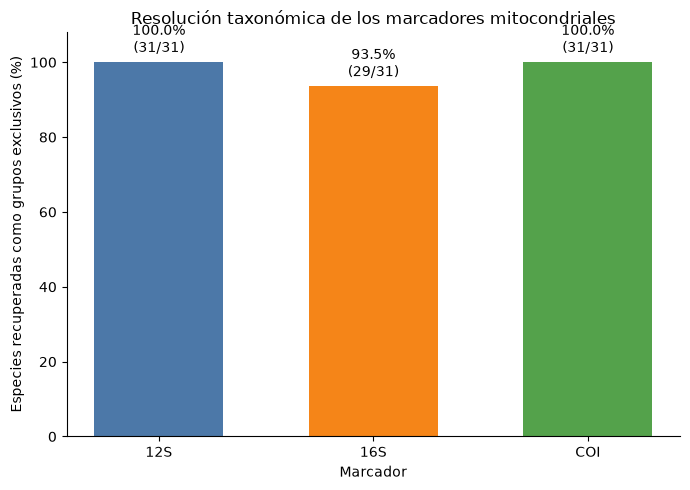

In [56]:
# =========================
# FIGURA
# RESOLUCIÓN TAXONÓMICA
# =========================

colores = {
    "12S": "#4C78A8",
    "16S": "#F58518",
    "COI": "#54A24B"
}

datos_figura = resumen_resolucion.copy()

fig, ax = plt.subplots(figsize=(7, 5))

barras = ax.bar(
    datos_figura["gen"].astype(str),
    datos_figura["porcentaje_exclusivas"],
    color=[
        colores[gen]
        for gen in datos_figura["gen"].astype(str)
    ],
    width=0.6
)

# Valores sobre las barras
for barra, (_, fila) in zip(
    barras,
    datos_figura.iterrows()
):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 1.5,
        f'{fila["porcentaje_exclusivas"]:.1f}%\n'
        f'({int(fila["especies_exclusivas"])}/'
        f'{int(fila["especies_evaluables"])})',
        ha="center",
        va="bottom",
        fontsize=10
    )

ax.set_ylabel(
    "Especies recuperadas como grupos exclusivos (%)"
)

ax.set_xlabel("Marcador")

ax.set_ylim(0, 108)

ax.set_title(
    "Resolución taxonómica de los marcadores mitocondriales"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

# Guardado
ruta_figuras = FIGURAS / "03_resolucion_taxonomica"

plt.savefig(
    ruta_figuras / "resolucion_taxonomica.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    ruta_figuras / "resolucion_taxonomica.pdf",
    bbox_inches="tight"
)

plt.show()

# 5. Regiones discriminatorias

Se evaluó la presencia de regiones potencialmente discriminatorias dentro de los marcadores 12S, 16S y COI mediante un análisis de ventanas deslizantes.

Para cada especie no nativa se analizó la variabilidad dentro de la especie objetivo y su diferenciación respecto de las restantes especies presentes en el conjunto de datos, incluyendo tanto especies no nativas como especies nativas de contraste.

El análisis se orientó a identificar regiones que combinaran baja variabilidad intraespecífica con elevada diferenciación respecto de la especie más similar en cada ventana. De esta manera, la capacidad discriminatoria no se evaluó únicamente mediante la divergencia promedio frente al conjunto de especies, sino considerando el contraste más restrictivo para cada especie objetivo.

Se utilizaron ventanas de 25 pb con desplazamiento de una posición.

In [57]:
# =========================
# P-DISTANCE EN VENTANAS
# =========================

def calcular_p_distance_ventana(seq1, seq2, inicio, fin):

    ventana1 = seq1[inicio:fin]
    ventana2 = seq2[inicio:fin]

    return calcular_p_distance(
        ventana1,
        ventana2
    )

In [58]:
# =========================
# ANÁLISIS DE UNA VENTANA
# PARA UNA ESPECIE OBJETIVO
# =========================

def analizar_ventana_especie(
    registros,
    especie_objetivo,
    inicio,
    fin
):

    # Separar secuencias objetivo y secuencias de contraste
    objetivo = []
    contraste = []

    for registro in registros:

        especie, tipo = extraer_metadatos_id(registro.id)

        if especie == especie_objetivo:
            objetivo.append(registro)
        else:
            contraste.append((registro, especie, tipo))


    # -------------------------
    # VARIABILIDAD INTRA
    # -------------------------

    distancias_intra = []
    sitios_intra = []

    if len(objetivo) >= 2:

        for seq1, seq2 in combinations(objetivo, 2):

            distancia, sitios = calcular_p_distance_ventana(
                str(seq1.seq),
                str(seq2.seq),
                inicio,
                fin
            )

            if not np.isnan(distancia):
                distancias_intra.append(distancia)
                sitios_intra.append(sitios)

        v_intra = (
            np.mean(distancias_intra)
            if distancias_intra
            else np.nan
        )

    else:
        v_intra = np.nan


    # -------------------------
    # CONTRASTE INTERESPECÍFICO
    # -------------------------

    comparaciones_contraste = []

    for seq_obj in objetivo:

        for seq_con, especie_con, tipo_con in contraste:

            distancia, sitios = calcular_p_distance_ventana(
                str(seq_obj.seq),
                str(seq_con.seq),
                inicio,
                fin
            )

            if not np.isnan(distancia):

                comparaciones_contraste.append({
                    "distancia": distancia,
                    "sitios": sitios,
                    "especie_contraste": especie_con,
                    "tipo_contraste": tipo_con
                })


    # Peor contraste = secuencia más similar al objetivo
    if comparaciones_contraste:

        peor = min(
            comparaciones_contraste,
            key=lambda x: x["distancia"]
        )

        d_min = peor["distancia"]
        especie_mas_cercana = peor["especie_contraste"]
        tipo_mas_cercano = peor["tipo_contraste"]
        sitios_contraste = peor["sitios"]

    else:

        d_min = np.nan
        especie_mas_cercana = None
        tipo_mas_cercano = None
        sitios_contraste = np.nan


    return {
        "v_intra": v_intra,
        "d_min": d_min,
        "especie_mas_cercana": especie_mas_cercana,
        "tipo_mas_cercano": tipo_mas_cercano,
        "sitios_intra_min": (
            min(sitios_intra)
            if sitios_intra
            else np.nan
        ),
        "sitios_contraste": sitios_contraste
    }

In [76]:
# =========================
# BARRIDO DE VENTANAS
# DISCRIMINATORIAS
# =========================

TAM_VENTANA = 25
PASO = 1

resultados_ventanas = []

for gen, registros in alineamientos.items():

    longitud_alineamiento = len(registros[0].seq)

    especies_objetivo = sorted({
        extraer_metadatos_id(registro.id)[0]
        for registro in registros
        if extraer_metadatos_id(registro.id)[1] == "no_nativa"
    })

    print(
        f"\n{gen}: {longitud_alineamiento} posiciones | "
        f"{len(especies_objetivo)} especies"
    )

    for n, especie in enumerate(especies_objetivo, start=1):

        print(
            f"  {n:02d}/{len(especies_objetivo)} "
            f"{especie}"
        )

        for inicio in range(
            0,
            longitud_alineamiento - TAM_VENTANA + 1,
            PASO
        ):

            fin = inicio + TAM_VENTANA

            resultado = analizar_ventana_especie(
                registros,
                especie,
                inicio,
                fin
            )

            resultados_ventanas.append({
                "gen": gen,
                "especie": especie,

                # Coordenadas del alineamiento
                # expresadas como 1-based inclusivas
                "inicio_alineamiento": inicio + 1,
                "fin_alineamiento": fin,

                "v_intra": resultado["v_intra"],
                "d_min": resultado["d_min"],

                "especie_mas_cercana":
                    resultado["especie_mas_cercana"],

                "tipo_mas_cercano":
                    resultado["tipo_mas_cercano"],

                "sitios_intra_min":
                    resultado["sitios_intra_min"],

                "sitios_contraste":
                    resultado["sitios_contraste"]
            })


ventanas = pd.DataFrame(resultados_ventanas)

ventanas["gen"] = pd.Categorical(
    ventanas["gen"],
    categories=["12S", "16S", "COI"],
    ordered=True
)

print("\nBarrido finalizado.")
print(f"Total de ventanas evaluadas: {len(ventanas):,}")

display(ventanas.head())


12S: 1059 posiciones | 33 especies
  01/33 Acipenser baerii
  02/33 Acipenser gueldenstaedtii
  03/33 Ameiurus nebulosus
  04/33 Carassius auratus
  05/33 Clarias gariepinus
  06/33 Coregonus clupeaformis
  07/33 Ctenopharyngodon idella
  08/33 Cyprinus Carpio
  09/33 Danio Rerio
  10/33 Gambusia affinis
  11/33 Gambusia holbrooki
  12/33 Huso huso
  13/33 Hypophthalmichthys molitrix
  14/33 Hypophthalmichthys nobilis
  15/33 Ictalurus punctatus
  16/33 Micropterus salmoides
  17/33 Morone saxatilis
  18/33 Oncorhynchus gorbuscha
  19/33 Oncorhynchus kisutch
  20/33 Oncorhynchus masou
  21/33 Oncorhynchus mykiss
  22/33 Oncorhynchus nerka
  23/33 Oncorhynchus tshawytscha
  24/33 Oreochromis niloticus
  25/33 Oryzias latipes
  26/33 Poecilia reticulata
  27/33 Rocío octofasciata
  28/33 Salmo salar
  29/33 Salmo trutta
  30/33 Salvelinus alpinus
  31/33 Salvelinus fontinalis
  32/33 Salvelinus namaycush
  33/33 Xiphophorus maculatus

16S: 2246 posiciones | 33 especies
  01/33 Acipenser

,gen,especie,inicio_alineamiento,fin_alineamiento,v_intra,d_min,especie_mas_cercana,tipo_mas_cercano,sitios_intra_min,sitios_contraste
0,12S,Acipenser baerii,1,25,0.0,0.0,Acipenser gueldenstaedtii,no_nativa,3.0,3.0
1,12S,Acipenser baerii,2,26,0.0,0.0,Acipenser gueldenstaedtii,no_nativa,2.0,2.0
2,12S,Acipenser baerii,3,27,0.0,0.0,Acipenser gueldenstaedtii,no_nativa,1.0,1.0
3,12S,Acipenser baerii,4,28,NaN,NaN,NaN,NaN,NaN,NaN
4,12S,Acipenser baerii,5,29,NaN,NaN,NaN,NaN,NaN,NaN


In [85]:
# =========================
# FILTRADO POR COBERTURA
# DE LA VENTANA
# =========================

MIN_SITIOS = 20

ventanas["ventana_informativa"] = (
    (ventanas["sitios_contraste"] >= MIN_SITIOS) &
    (
        ventanas["sitios_intra_min"].isna() |
        (ventanas["sitios_intra_min"] >= MIN_SITIOS)
    )
)

resumen_cobertura = (
    ventanas
    .groupby("gen", observed=True)
    .agg(
        ventanas_totales=("ventana_informativa", "size"),
        ventanas_informativas=("ventana_informativa", "sum")
    )
    .reset_index()
)

resumen_cobertura["porcentaje_informativas"] = (
    resumen_cobertura["ventanas_informativas"] /
    resumen_cobertura["ventanas_totales"] * 100
)

display(resumen_cobertura.round(2))

,gen,ventanas_totales,ventanas_informativas,porcentaje_informativas
0,12S,34155,29615,86.71
1,16S,73326,52311,71.34
2,COI,66528,50322,75.64


In [86]:
# =========================
# MEJOR REGIÓN CONSERVADA Y
# DISCRIMINATORIA POR ESPECIE
# =========================

ventanas_validas = ventanas[
    ventanas["ventana_informativa"]
].copy()

# Para especies con información intraespecífica:
# conservar únicamente ventanas sin variación dentro de la especie.
#
# Para especies con n=1:
# v_intra es NaN y se mantienen, pero deben interpretarse
# como "conservación intraespecífica no evaluable".
ventanas_candidatas = ventanas_validas[
    ventanas_validas["v_intra"].isna() |
    np.isclose(ventanas_validas["v_intra"], 0.0)
].copy()


# Para cada especie y marcador, seleccionar la ventana
# con el mayor d_min (mejor peor-contraste)
idx_mejores = (
    ventanas_candidatas
    .groupby(["gen", "especie"], observed=True)["d_min"]
    .idxmax()
)

mejor_region_especie = (
    ventanas_candidatas
    .loc[idx_mejores]
    .sort_values(["gen", "especie"])
    .reset_index(drop=True)
)


display(
    mejor_region_especie[
        [
            "gen",
            "especie",
            "inicio_alineamiento",
            "fin_alineamiento",
            "v_intra",
            "d_min",
            "especie_mas_cercana",
            "tipo_mas_cercano"
        ]
    ].head(15)
)

print(
    "\nEspecies con región candidata por marcador:"
)

display(
    mejor_region_especie
    .groupby("gen", observed=True)["especie"]
    .nunique()
    .reset_index(name="n_especies")
)

,gen,especie,inicio_alineamiento,fin_alineamiento,v_intra,d_min,especie_mas_cercana,tipo_mas_cercano
0,12S,Acipenser baerii,949,973,0.0,0.050000,Acipenser gueldenstaedtii,no_nativa
1,12S,Acipenser gueldenstaedtii,51,75,0.0,0.000000,Acipenser baerii,no_nativa
2,12S,Ameiurus nebulosus,951,975,0.0,0.300000,Clarias gariepinus,no_nativa
3,12S,Carassius auratus,975,999,0.0,0.200000,Cyprinus Carpio,no_nativa
4,12S,Clarias gariepinus,977,1001,NaN,0.363636,Gambusia affinis,no_nativa
5,12S,Coregonus clupeaformis,735,759,0.0,0.160000,Salmo salar,no_nativa
6,12S,Ctenopharyngodon idella,444,468,0.0,0.130435,Ameiurus nebulosus,no_nativa
7,12S,Cyprinus Carpio,975,999,0.0,0.150000,Hypophthalmichthys nobilis,no_nativa
8,12S,Danio Rerio,427,451,0.0,0.318182,Hypophthalmichthys molitrix,no_nativa
9,12S,Gambusia affinis,975,999,0.0,0.100000,Gambusia holbrooki,no_nativa



Especies con región candidata por marcador:


,gen,n_especies
0,12S,33
1,16S,33
2,COI,33


In [87]:
# =========================
# CAPACIDAD DISCRIMINATORIA
# DE LAS MEJORES REGIONES
# =========================

resumen_regiones_marcador = (
    mejor_region_especie
    .groupby("gen", observed=True)
    .agg(
        n_especies=("especie", "nunique"),
        d_min_media=("d_min", "mean"),
        d_min_mediana=("d_min", "median"),
        d_min_minima=("d_min", "min"),
        d_min_maxima=("d_min", "max"),
        especies_dmin_cero=(
            "d_min",
            lambda x: np.isclose(x, 0.0).sum()
        )
    )
    .reset_index()
)

display(
    resumen_regiones_marcador.round(4)
)

,gen,n_especies,d_min_media,d_min_mediana,d_min_minima,d_min_maxima,especies_dmin_cero
0,12S,33,0.1576,0.1250,0.00,0.3636,2
1,16S,33,0.2146,0.1905,0.05,0.5200,0
2,COI,33,0.1768,0.1600,0.04,0.4500,0


In [88]:
# =========================
# GUARDADO DE RESULTADOS
# REGIONES DISCRIMINATORIAS
# =========================

carpeta_resultados = (
    RESULTADOS / "04_regiones_discriminatorias"
)

# Barrido completo
ventanas.to_csv(
    carpeta_resultados /
    "ventanas_25pb_completas.csv",
    index=False
)

# Mejor región por especie y marcador
mejor_region_especie.to_csv(
    carpeta_resultados /
    "mejor_region_por_especie.csv",
    index=False
)

# Resumen por marcador
resumen_regiones_marcador.to_csv(
    carpeta_resultados /
    "resumen_regiones_por_marcador.csv",
    index=False
)

print("Resultados guardados correctamente.")

Resultados guardados correctamente.


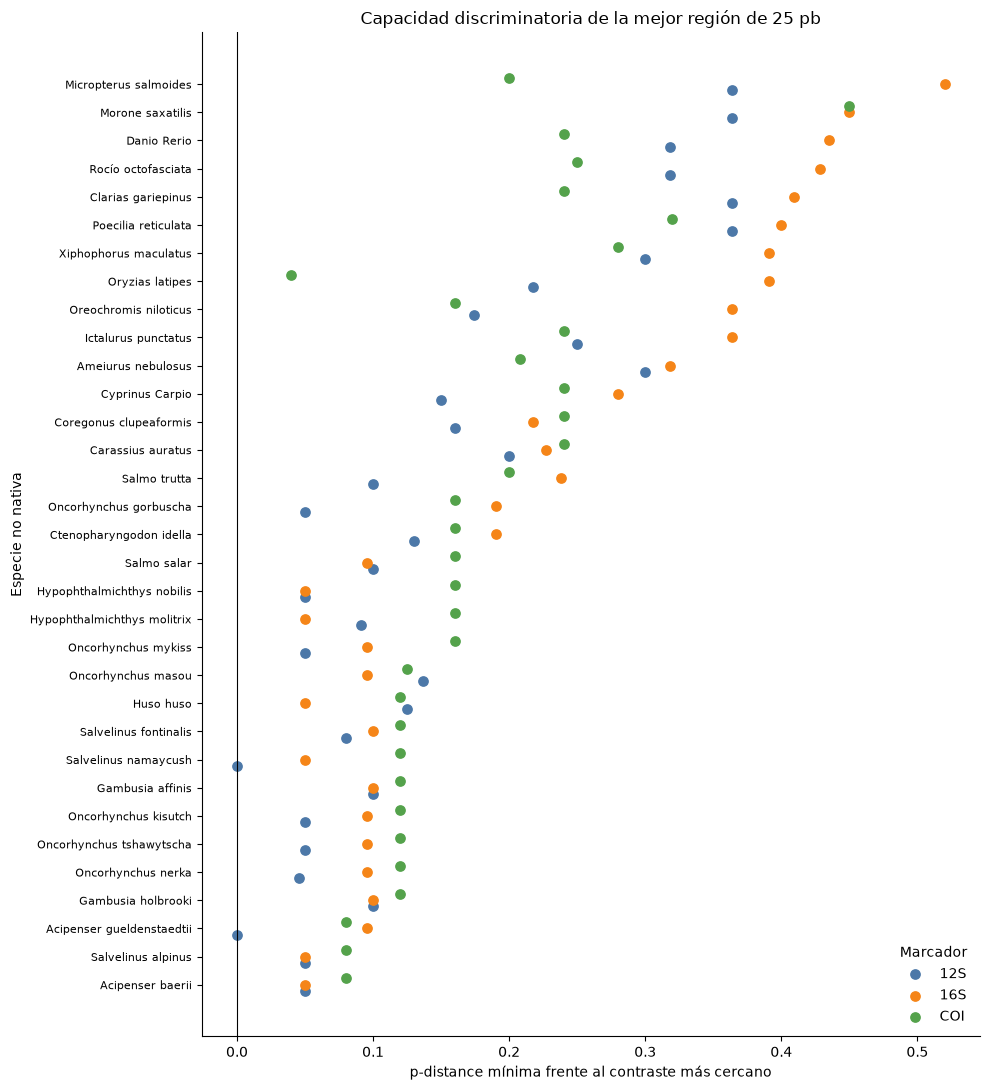

In [89]:
# =========================
# FIGURA
# MEJOR REGIÓN DISCRIMINATORIA
# POR ESPECIE
# =========================

datos_figura = mejor_region_especie.pivot(
    index="especie",
    columns="gen",
    values="d_min"
)[["12S", "16S", "COI"]]

# Ordenar especies según su mejor valor global
datos_figura["maximo"] = datos_figura.max(axis=1)

datos_figura = (
    datos_figura
    .sort_values("maximo", ascending=True)
    .drop(columns="maximo")
)

colores = {
    "12S": "#4C78A8",
    "16S": "#F58518",
    "COI": "#54A24B"
}

fig, ax = plt.subplots(figsize=(10, 11))

y = np.arange(len(datos_figura))

desplazamiento = 0.22

for gen, offset in zip(
    ["12S", "16S", "COI"],
    [-desplazamiento, 0, desplazamiento]
):

    ax.scatter(
        datos_figura[gen],
        y + offset,
        label=gen,
        color=colores[gen],
        s=45
    )

ax.set_yticks(y)
ax.set_yticklabels(
    datos_figura.index,
    fontsize=8
)

ax.set_xlabel(
    "p-distance mínima frente al contraste más cercano"
)

ax.set_ylabel("Especie no nativa")

ax.set_title(
    "Capacidad discriminatoria de la mejor región de 25 pb"
)

ax.axvline(
    0,
    color="black",
    linewidth=0.8
)

ax.legend(
    title="Marcador",
    frameon=False
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

ruta_figuras = (
    FIGURAS / "04_regiones_discriminatorias"
)

plt.savefig(
    ruta_figuras /
    "mejor_region_discriminatoria_por_especie.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    ruta_figuras /
    "mejor_region_discriminatoria_por_especie.pdf",
    bbox_inches="tight"
)

plt.show()

# 6. Síntesis para la selección del marcador

La selección del marcador se realizó integrando los resultados obtenidos en los distintos niveles de análisis, sin establecer un índice ponderado a priori.

Para cada marcador se consideraron de manera conjunta:

1. la longitud de las secuencias;
2. la variabilidad intraespecífica de las especies no nativas;
3. la divergencia interespecífica entre especies no nativas;
4. la divergencia entre especies no nativas y especies nativas de contraste;
5. la resolución taxonómica observada mediante agrupamiento exclusivo;
6. la capacidad discriminatoria de regiones conservadas de 25 pb.

La selección se basó en la convergencia de estas evidencias, priorizando la capacidad de diferenciar las especies no nativas respecto de las restantes especies del conjunto de referencia y la disponibilidad de regiones conservadas dentro de la especie objetivo con potencial para el posterior diseño de primers especie-específicos.

In [90]:
# =========================
# TABLA DE SÍNTESIS
# =========================

sintesis = pd.DataFrame({
    "gen": ["12S", "16S", "COI"],

    "longitud_media_no_nativa": [
        951.95,
        1680.80,
        1553.86
    ],

    "p_intra_media": [
        0.002686,
        0.004223,
        0.008234
    ],

    "p_inter_no_nativas_media": [
        0.166857,
        0.200809,
        0.190434
    ],

    "p_no_nativa_nativa_media": [
        0.188277,
        0.228014,
        0.201457
    ],

    "agrupamiento_exclusivo_pct": [
        100.0,
        93.548387,
        100.0
    ],

    "mejor_region_dmin_media": [
        0.1576,
        0.2146,
        0.1768
    ],

    "mejor_region_dmin_mediana": [
        0.1250,
        0.1905,
        0.1600
    ],

    "mejor_region_dmin_minima": [
        0.00,
        0.05,
        0.04
    ],

    "especies_dmin_cero": [
        2,
        0,
        0
    ]
})

display(sintesis.round(4))

sintesis.to_csv(
    RESULTADOS /
    "05_sintesis" /
    "sintesis_seleccion_marcador.csv",
    index=False
)

,gen,longitud_media_no_nativa,p_intra_media,p_inter_no_nativas_media,p_no_nativa_nativa_media,agrupamiento_exclusivo_pct,mejor_region_dmin_media,mejor_region_dmin_mediana,mejor_region_dmin_minima,especies_dmin_cero
0,12S,951.95,0.0027,0.1669,0.1883,100.0000,0.1576,0.1250,0.00,2
1,16S,1680.80,0.0042,0.2008,0.2280,93.5484,0.2146,0.1905,0.05,0
2,COI,1553.86,0.0082,0.1904,0.2015,100.0000,0.1768,0.1600,0.04,0


In [91]:
# =========================
# MATRIZ DE CRITERIOS
# PARA EL ÍNDICE
# =========================

criterios = pd.DataFrame({
    "gen": ["12S", "16S", "COI"],

    # A. Conservación intraespecífica
    # Menor p-distance = mejor
    "intra": [
        0.002686,
        0.004223,
        0.008234
    ],

    # B. Divergencia entre especies no nativas
    # Mayor = mejor
    "inter_no_nativas": [
        0.166857,
        0.200809,
        0.190434
    ],

    # C. Divergencia no nativa - nativa
    # Mayor = mejor
    "no_nativa_nativa": [
        0.188277,
        0.228014,
        0.201457
    ],

    # D. Resolución taxonómica
    # Expresada como proporción
    "resolucion_taxonomica": [
        1.000000,
        0.935484,
        1.000000
    ],

    # E. Capacidad discriminatoria regional
    # Media del mejor d_min de las 33 especies
    "region_discriminatoria": [
        0.1576,
        0.2146,
        0.1768
    ]
})

display(criterios.round(6))

,gen,intra,inter_no_nativas,no_nativa_nativa,resolucion_taxonomica,region_discriminatoria
0,12S,0.002686,0.166857,0.188277,1.000000,0.1576
1,16S,0.004223,0.200809,0.228014,0.935484,0.2146
2,COI,0.008234,0.190434,0.201457,1.000000,0.1768


In [92]:
# =========================
# NORMALIZACIÓN DE CRITERIOS
# =========================

criterios_norm = criterios.copy()

# A. Variabilidad intraespecífica
# Menor = mejor -> normalización inversa
inverso_intra = 1 / criterios["intra"]

criterios_norm["intra"] = (
    inverso_intra / inverso_intra.sum()
)


# B-E. Criterios donde mayor = mejor
criterios_directos = [
    "inter_no_nativas",
    "no_nativa_nativa",
    "resolucion_taxonomica",
    "region_discriminatoria"
]

for columna in criterios_directos:

    criterios_norm[columna] = (
        criterios[columna] /
        criterios[columna].sum()
    )


display(criterios_norm.round(4))


# Control: cada criterio debe sumar 1
print("\nSuma de cada criterio normalizado:")

display(
    criterios_norm[
        [
            "intra",
            "inter_no_nativas",
            "no_nativa_nativa",
            "resolucion_taxonomica",
            "region_discriminatoria"
        ]
    ]
    .sum()
    .round(6)
)

,gen,intra,inter_no_nativas,no_nativa_nativa,resolucion_taxonomica,region_discriminatoria
0,12S,0.5096,0.2990,0.3048,0.3407,0.2871
1,16S,0.3241,0.3598,0.3691,0.3187,0.3909
2,COI,0.1662,0.3412,0.3261,0.3407,0.3220



Suma de cada criterio normalizado:


intra                     1.0
inter_no_nativas          1.0
no_nativa_nativa          1.0
resolucion_taxonomica     1.0
region_discriminatoria    1.0
dtype: float64

In [93]:
# =========================
# ÍNDICE MULTICRITERIO
# PESOS IGUALES
# =========================

columnas_criterios = [
    "intra",
    "inter_no_nativas",
    "no_nativa_nativa",
    "resolucion_taxonomica",
    "region_discriminatoria"
]

pesos_iguales = np.repeat(
    1 / len(columnas_criterios),
    len(columnas_criterios)
)

indice_base = criterios_norm.copy()

indice_base["indice"] = (
    indice_base[columnas_criterios]
    .mul(pesos_iguales, axis=1)
    .sum(axis=1)
)

indice_base = (
    indice_base[
        ["gen", "indice"] + columnas_criterios
    ]
    .sort_values(
        "indice",
        ascending=False
    )
    .reset_index(drop=True)
)

indice_base["posicion"] = (
    np.arange(1, len(indice_base) + 1)
)

display(
    indice_base[
        ["posicion", "gen", "indice"]
    ].round(4)
)

print("\nPesos utilizados:")

for criterio, peso in zip(
    columnas_criterios,
    pesos_iguales
):
    print(f"{criterio}: {peso:.2f}")

,posicion,gen,indice
0,1,16S,0.3525
1,2,12S,0.3482
2,3,COI,0.2993



Pesos utilizados:
intra: 0.20
inter_no_nativas: 0.20
no_nativa_nativa: 0.20
resolucion_taxonomica: 0.20
region_discriminatoria: 0.20


In [94]:
# =========================
# ANÁLISIS DE SENSIBILIDAD
# 10.000 COMBINACIONES DE PESOS
# =========================

N_SIMULACIONES = 10_000
SEMILLA = 42

rng = np.random.default_rng(SEMILLA)

# Cada fila contiene 5 pesos aleatorios que suman 1
pesos_aleatorios = rng.dirichlet(
    alpha=np.ones(len(columnas_criterios)),
    size=N_SIMULACIONES
)

# Matriz:
# filas = marcadores
# columnas = criterios
matriz_puntuaciones = (
    criterios_norm
    .set_index("gen")[columnas_criterios]
)

# Índice de cada marcador en cada simulación
indices_simulados = (
    pesos_aleatorios @ matriz_puntuaciones.T.to_numpy()
)

# Marcador con mayor índice en cada simulación
marcadores = matriz_puntuaciones.index.to_numpy()

ganadores = marcadores[
    np.argmax(indices_simulados, axis=1)
]

# Guardamos cada simulación
sensibilidad = pd.DataFrame(
    pesos_aleatorios,
    columns=[
        "peso_intra",
        "peso_inter_no_nativas",
        "peso_no_nativa_nativa",
        "peso_resolucion_taxonomica",
        "peso_region_discriminatoria"
    ]
)

for i, gen in enumerate(marcadores):
    sensibilidad[f"indice_{gen}"] = indices_simulados[:, i]

sensibilidad["ganador"] = ganadores


# Resumen
resumen_sensibilidad = (
    sensibilidad["ganador"]
    .value_counts()
    .reindex(["12S", "16S", "COI"], fill_value=0)
    .rename_axis("gen")
    .reset_index(name="n_simulaciones")
)

resumen_sensibilidad["porcentaje"] = (
    resumen_sensibilidad["n_simulaciones"]
    / N_SIMULACIONES
    * 100
)

display(resumen_sensibilidad.round(2))


# Control de los pesos
print("\nSuma mínima y máxima de los pesos:")

suma_pesos = pesos_aleatorios.sum(axis=1)

print(f"Mínima: {suma_pesos.min():.6f}")
print(f"Máxima: {suma_pesos.max():.6f}")

,gen,n_simulaciones,porcentaje
0,12S,4048,40.48
1,16S,5922,59.22
2,COI,30,0.30



Suma mínima y máxima de los pesos:
Mínima: 1.000000
Máxima: 1.000000


In [95]:
# =========================
# PESOS SEGÚN MARCADOR GANADOR
# =========================

columnas_pesos = [
    "peso_intra",
    "peso_inter_no_nativas",
    "peso_no_nativa_nativa",
    "peso_resolucion_taxonomica",
    "peso_region_discriminatoria"
]

pesos_por_ganador = (
    sensibilidad
    .groupby("ganador")[columnas_pesos]
    .mean()
    .reindex(["12S", "16S", "COI"])
)

display(
    pesos_por_ganador.round(3)
)

,peso_intra,peso_inter_no_nativas,peso_no_nativa_nativa,peso_resolucion_taxonomica,peso_region_discriminatoria
ganador,,,,,
12S,0.351,0.148,0.151,0.222,0.128
16S,0.099,0.231,0.233,0.183,0.253
COI,0.010,0.141,0.055,0.720,0.074


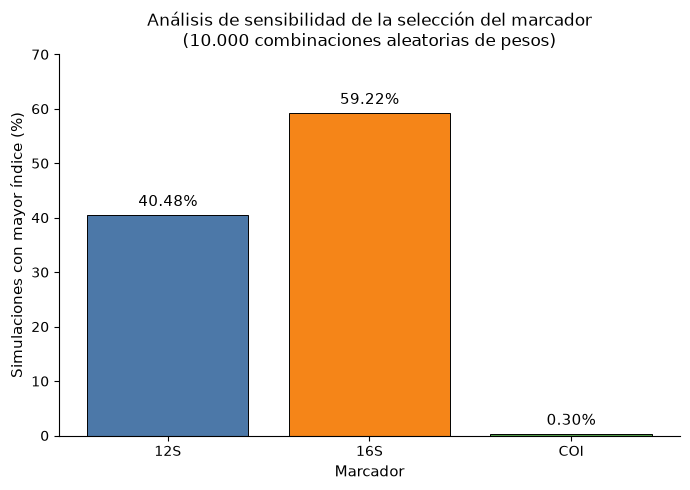

In [96]:
# =========================
# FIGURA
# ANÁLISIS DE SENSIBILIDAD
# =========================

colores = {
    "12S": "#4C78A8",
    "16S": "#F58518",
    "COI": "#54A24B"
}

fig, ax = plt.subplots(figsize=(7, 5))

genes = resumen_sensibilidad["gen"]
porcentajes = resumen_sensibilidad["porcentaje"]

barras = ax.bar(
    genes,
    porcentajes,
    color=[colores[g] for g in genes],
    edgecolor="black",
    linewidth=0.7
)

# Valores sobre las barras
for barra, porcentaje in zip(barras, porcentajes):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 1,
        f"{porcentaje:.2f}%",
        ha="center",
        va="bottom",
        fontsize=11
    )

ax.set_ylabel(
    "Simulaciones con mayor índice (%)",
    fontsize=11
)

ax.set_xlabel("Marcador", fontsize=11)

ax.set_title(
    "Análisis de sensibilidad de la selección del marcador\n"
    "(10.000 combinaciones aleatorias de pesos)",
    fontsize=12
)

ax.set_ylim(0, 70)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

# Guardar
ruta_png = (
    FIGURAS
    / "05_sintesis"
    / "sensibilidad_pesos_aleatorios.png"
)

ruta_pdf = (
    FIGURAS
    / "05_sintesis"
    / "sensibilidad_pesos_aleatorios.pdf"
)

plt.savefig(
    ruta_png,
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    ruta_pdf,
    bbox_inches="tight"
)

plt.show()

In [97]:
print("TAM_VENTANA =", TAM_VENTANA)

print(
    "Longitudes observadas de las ventanas:",
    (
        ventanas["fin_alineamiento"]
        - ventanas["inicio_alineamiento"]
        + 1
    ).unique()
)

print("\nCantidad total de ventanas:")
print(len(ventanas))

print("\nResumen actual:")
display(resumen_regiones_marcador.round(4))

TAM_VENTANA = 25
Longitudes observadas de las ventanas: [25]

Cantidad total de ventanas:
174009

Resumen actual:


,gen,n_especies,d_min_media,d_min_mediana,d_min_minima,d_min_maxima,especies_dmin_cero
0,12S,33,0.1576,0.1250,0.00,0.3636,2
1,16S,33,0.2146,0.1905,0.05,0.5200,0
2,COI,33,0.1768,0.1600,0.04,0.4500,0


In [98]:
# ==========================================
# MAPA DE REGIONES DISCRIMINATORIAS
# Preparación de matrices especie × posición
# ==========================================

genes = ["12S", "16S", "COI"]

# Orden común de especies
especies_orden = sorted(
    ventanas_candidatas["especie"].unique()
)

# Longitudes de los alineamientos
longitudes_alineamiento = {
    "12S": 1059,
    "16S": 2246,
    "COI": 2040
}

matrices_regiones = {}

for gen in genes:

    datos_gen = ventanas_candidatas[
        ventanas_candidatas["gen"] == gen
    ].copy()

    longitud = longitudes_alineamiento[gen]

    # filas = especies
    # columnas = posiciones del alineamiento
    matriz = np.full(
        (len(especies_orden), longitud),
        np.nan
    )

    indice_especie = {
        especie: i
        for i, especie in enumerate(especies_orden)
    }

    for fila in datos_gen.itertuples():

        i = indice_especie[fila.especie]

        inicio = int(fila.inicio_alineamiento)
        fin = int(fila.fin_alineamiento)

        valor = float(fila.d_min)

        # Si varias ventanas cubren una misma posición,
        # conservamos el mayor d_min
        matriz[i, inicio:fin] = np.fmax(
            matriz[i, inicio:fin],
            valor
        )

    matrices_regiones[gen] = matriz


# =========================
# CONTROL
# =========================

for gen in genes:

    matriz = matrices_regiones[gen]

    posiciones_con_candidato = np.sum(
        ~np.isnan(matriz)
    )

    especies_con_candidato = np.sum(
        np.any(~np.isnan(matriz), axis=1)
    )

    print(
        f"{gen}: "
        f"{matriz.shape[0]} especies × "
        f"{matriz.shape[1]} posiciones | "
        f"{posiciones_con_candidato:,} celdas con candidato | "
        f"{especies_con_candidato} especies con candidato"
    )


12S: 33 especies × 1059 posiciones | 32,567 celdas con candidato | 33 especies con candidato
16S: 33 especies × 2246 posiciones | 56,960 celdas con candidato | 33 especies con candidato
COI: 33 especies × 2040 posiciones | 48,024 celdas con candidato | 33 especies con candidato


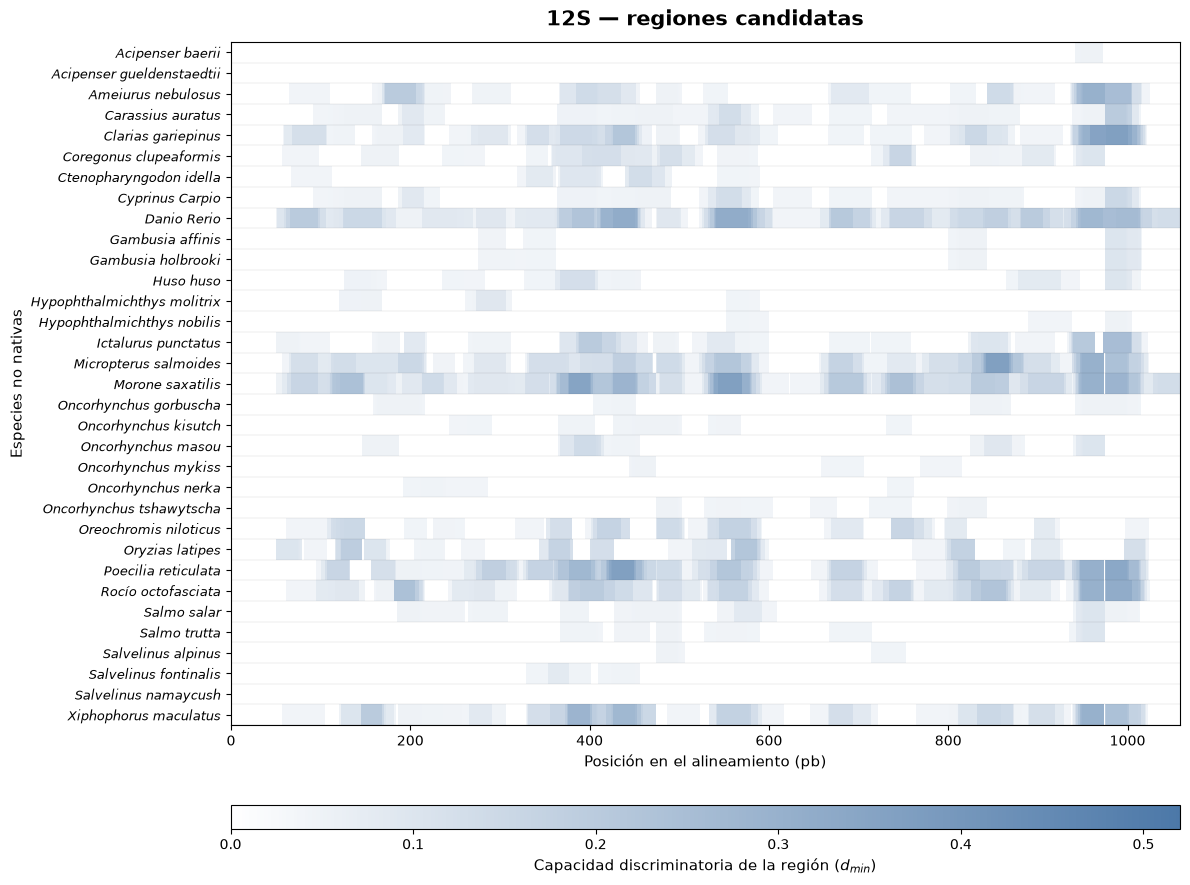

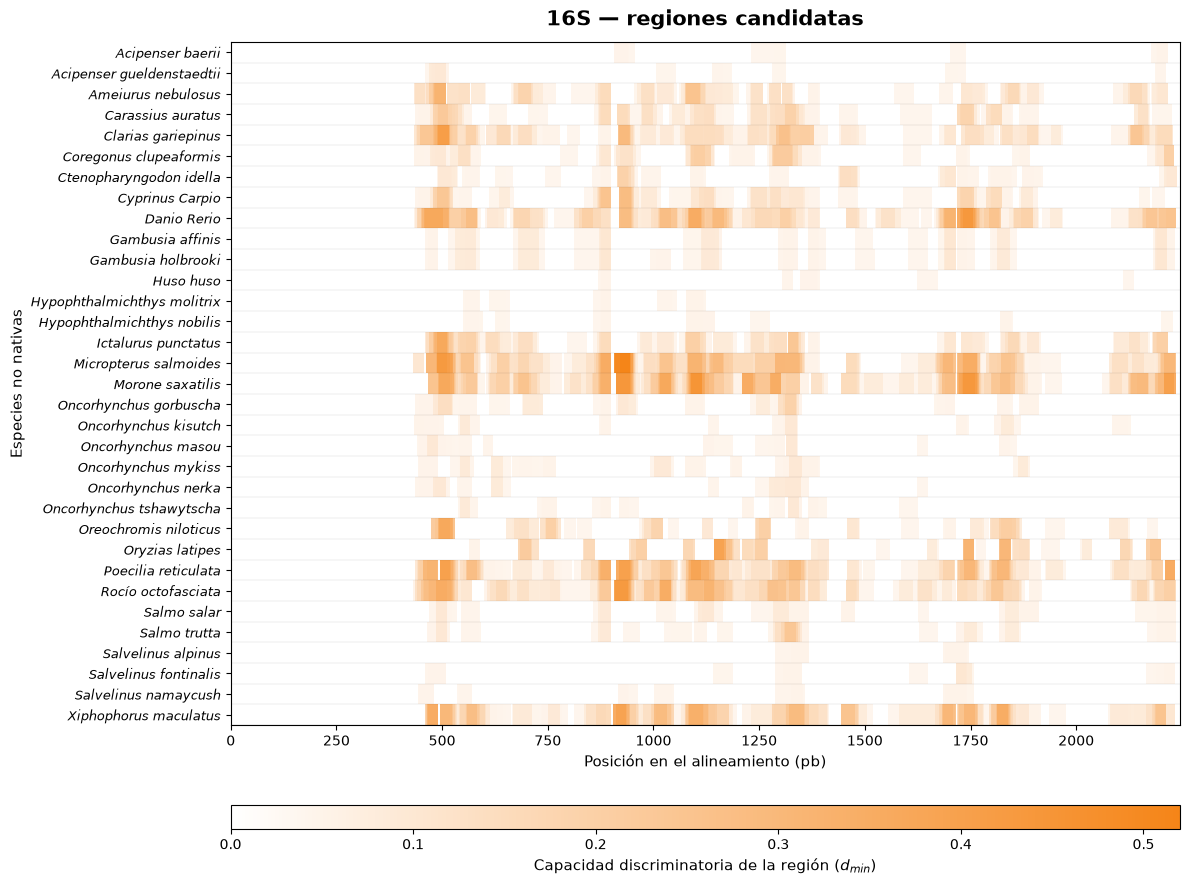

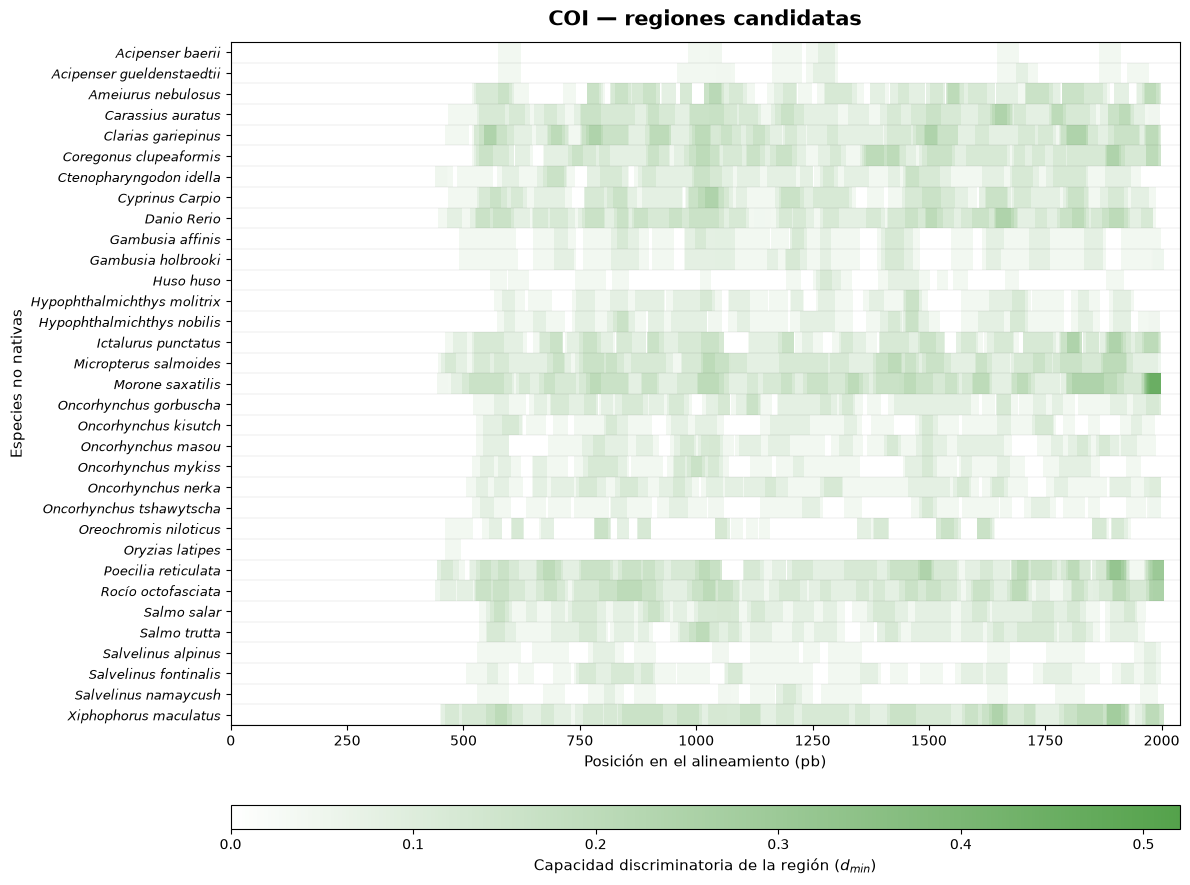

In [99]:
# ==========================================
# MAPAS INDIVIDUALES DE REGIONES
# DISCRIMINATORIAS
# ==========================================

from matplotlib.colors import LinearSegmentedColormap, Normalize

colores_marcadores = {
    "12S": "#4C78A8",
    "16S": "#F58518",
    "COI": "#54A24B"
}

# Misma escala para los tres marcadores
vmin = 0

vmax = max(
    np.nanmax(matrices_regiones[gen])
    for gen in genes
)

norm = Normalize(vmin=vmin, vmax=vmax)


# Crear un mapa de color blanco -> color del marcador
def crear_cmap(color):

    return LinearSegmentedColormap.from_list(
        "cmap_marcador",
        ["#FFFFFF", color]
    )


for gen in genes:

    matriz = matrices_regiones[gen]

    cmap = crear_cmap(
        colores_marcadores[gen]
    )

    fig, ax = plt.subplots(
        figsize=(12, 9)
    )

    im = ax.imshow(
        matriz,
        aspect="auto",
        interpolation="nearest",
        cmap=cmap,
        norm=norm,
        origin="upper"
    )

    # --------------------------
    # EJE Y: especies
    # --------------------------

    ax.set_yticks(
        np.arange(len(especies_orden))
    )

    ax.set_yticklabels(
        especies_orden,
        fontsize=9,
        fontstyle="italic"
    )

    ax.set_ylabel(
        "Especies no nativas",
        fontsize=11
    )

    # --------------------------
    # EJE X
    # --------------------------

    ax.set_xlabel(
        "Posición en el alineamiento (pb)",
        fontsize=11
    )

    # Separación suave entre especies
    for y in np.arange(
        0.5,
        len(especies_orden),
        1
    ):

        ax.axhline(
            y,
            linewidth=0.25,
            alpha=0.20,
            color="black"
        )

    # --------------------------
    # TÍTULO
    # --------------------------

    ax.set_title(
        f"{gen} — regiones candidatas",
        fontsize=15,
        fontweight="bold",
        pad=12
    )

    # --------------------------
    # BARRA DE COLOR
    # --------------------------

    cbar = fig.colorbar(
        im,
        ax=ax,
        orientation="horizontal",
        fraction=0.045,
        pad=0.10,
        aspect=40
    )

    cbar.set_label(
        r"Capacidad discriminatoria de la región ($d_{min}$)",
        fontsize=11
    )

    plt.tight_layout()

    # --------------------------
    # GUARDAR
    # --------------------------

    nombre = f"regiones_discriminatorias_{gen}"

    plt.savefig(
        FIGURAS
        / "04_regiones_discriminatorias"
        / f"{nombre}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.savefig(
        FIGURAS
        / "04_regiones_discriminatorias"
        / f"{nombre}.pdf",
        bbox_inches="tight"
    )

    plt.show()

In [100]:
display(resumen_cobertura.round(2))

display(
    mejor_region_especie
    .groupby("gen", observed=True)["especie"]
    .nunique()
    .reset_index(name="n_especies")
)

display(resumen_regiones_marcador.round(4))

,gen,ventanas_totales,ventanas_informativas,porcentaje_informativas
0,12S,34155,29615,86.71
1,16S,73326,52311,71.34
2,COI,66528,50322,75.64


,gen,n_especies
0,12S,33
1,16S,33
2,COI,33


,gen,n_especies,d_min_media,d_min_mediana,d_min_minima,d_min_maxima,especies_dmin_cero
0,12S,33,0.1576,0.1250,0.00,0.3636,2
1,16S,33,0.2146,0.1905,0.05,0.5200,0
2,COI,33,0.1768,0.1600,0.04,0.4500,0


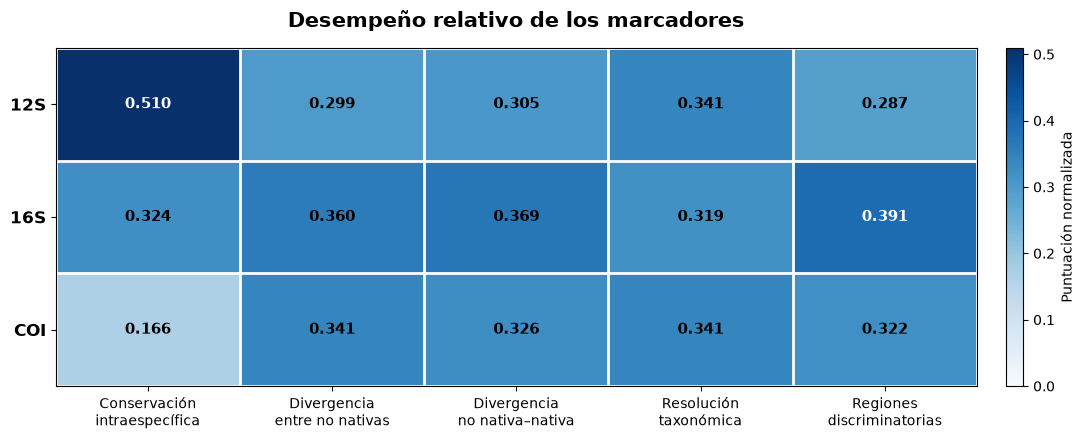

In [101]:
# ==========================================
# FIGURA: DESEMPEÑO MULTICRITERIO
# ==========================================

# Orden de marcadores
orden_genes = ["12S", "16S", "COI"]

columnas_heatmap = [
    "intra",
    "inter_no_nativas",
    "no_nativa_nativa",
    "resolucion_taxonomica",
    "region_discriminatoria"
]

etiquetas = [
    "Conservación\nintraespecífica",
    "Divergencia\nentre no nativas",
    "Divergencia\nno nativa–nativa",
    "Resolución\ntaxonómica",
    "Regiones\ndiscriminatorias"
]

datos_heatmap = (
    criterios_norm
    .set_index("gen")
    .loc[orden_genes, columnas_heatmap]
)

fig, ax = plt.subplots(figsize=(11, 4.5))

im = ax.imshow(
    datos_heatmap.values,
    cmap="Blues",
    aspect="auto",
    vmin=0,
    vmax=datos_heatmap.values.max()
)

# Etiquetas
ax.set_xticks(
    np.arange(len(etiquetas))
)

ax.set_xticklabels(
    etiquetas,
    fontsize=10
)

ax.set_yticks(
    np.arange(len(orden_genes))
)

ax.set_yticklabels(
    orden_genes,
    fontsize=12,
    fontweight="bold"
)

# Valores dentro de cada celda
for i in range(len(orden_genes)):
    for j in range(len(columnas_heatmap)):

        valor = datos_heatmap.iloc[i, j]

        # Texto blanco en celdas oscuras
        color_texto = (
            "white"
            if valor > 0.38
            else "black"
        )

        ax.text(
            j,
            i,
            f"{valor:.3f}",
            ha="center",
            va="center",
            fontsize=11,
            fontweight="bold",
            color=color_texto
        )

# Separación entre celdas
ax.set_xticks(
    np.arange(-0.5, len(columnas_heatmap), 1),
    minor=True
)

ax.set_yticks(
    np.arange(-0.5, len(orden_genes), 1),
    minor=True
)

ax.grid(
    which="minor",
    color="white",
    linewidth=2
)

ax.tick_params(
    which="minor",
    bottom=False,
    left=False
)

ax.set_title(
    "Desempeño relativo de los marcadores",
    fontsize=15,
    fontweight="bold",
    pad=15
)

# Barra de color
cbar = fig.colorbar(
    im,
    ax=ax,
    fraction=0.035,
    pad=0.03
)

cbar.set_label(
    "Puntuación normalizada",
    fontsize=10
)

plt.tight_layout()

# Guardar
plt.savefig(
    FIGURAS
    / "05_sintesis"
    / "heatmap_desempeno_multicriterio.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    FIGURAS
    / "05_sintesis"
    / "heatmap_desempeno_multicriterio.pdf",
    bbox_inches="tight"
)

plt.show()

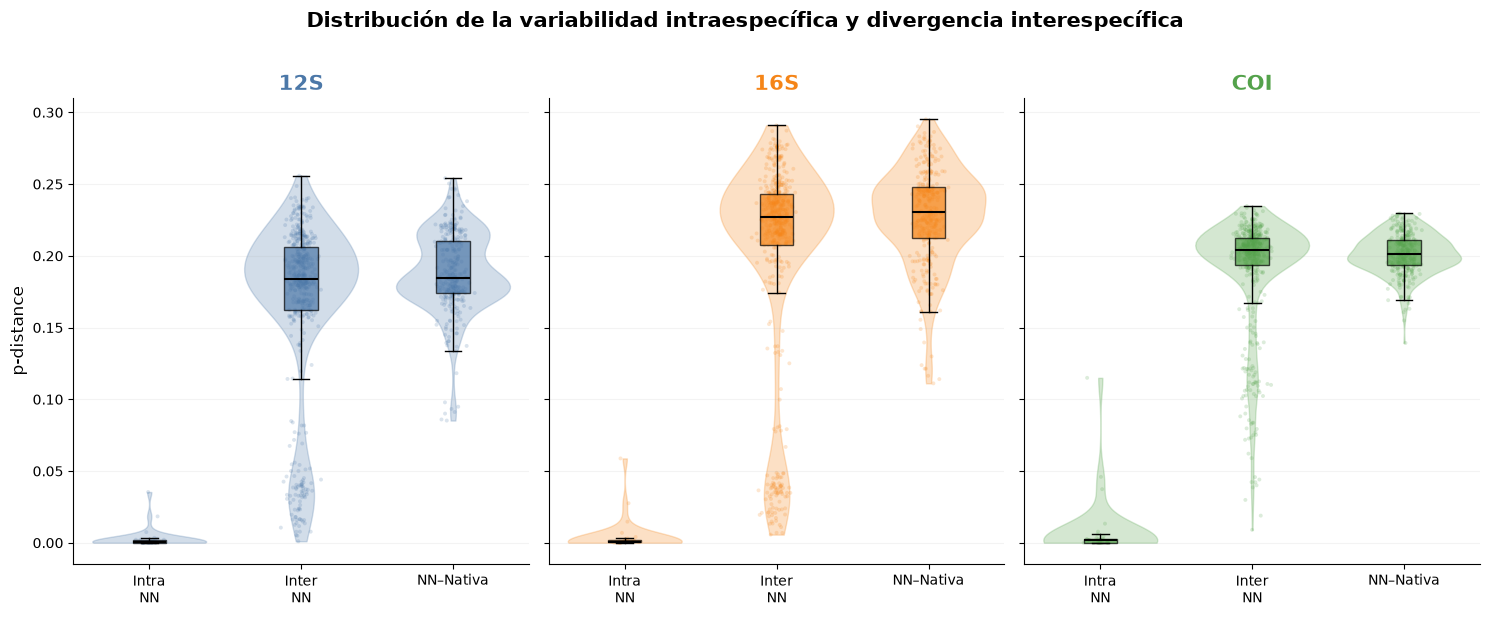

In [ ]:
# ==========================================
# FIGURA: DISTRIBUCIONES DE p-DISTANCE
# ==========================================

colores_marcadores = {
    "12S": "#4C78A8",
    "16S": "#F58518",
    "COI": "#54A24B"
}

genes = ["12S", "16S", "COI"]


# ------------------------------------------
# 1. RESUMIR A NIVEL BIOLÓGICO COMPARABLE
# ------------------------------------------

# Intra: una observación por especie
intra_fig = (
    distancias_intra
    .groupby(["gen", "especie"], as_index=False)
    ["p_distance"]
    .mean()
)

intra_fig["comparacion"] = "Intra NN"


# Inter no nativas:
# una observación por par de especies
inter_fig = (
    distancias_inter_no_nativas
    .groupby(
        ["gen", "especie_1", "especie_2"],
        as_index=False
    )
    ["p_distance"]
    .mean()
)

inter_fig["comparacion"] = "Inter NN"


# No nativa - nativa:
# una observación por par de especies
contraste_fig = (
    distancias_contraste_nativas
    .groupby(
        ["gen", "especie_no_nativa", "especie_nativa"],
        as_index=False
    )
    ["p_distance"]
    .mean()
)

contraste_fig["comparacion"] = "NN–Nativa"


# Unificar
datos_distancias_fig = pd.concat(
    [
        intra_fig[["gen", "comparacion", "p_distance"]],
        inter_fig[["gen", "comparacion", "p_distance"]],
        contraste_fig[["gen", "comparacion", "p_distance"]]
    ],
    ignore_index=True
)


# ------------------------------------------
# 2. FIGURA
# ------------------------------------------

fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 6),
    sharey=True
)

orden_comparaciones = [
    "Intra NN",
    "Inter NN",
    "NN–Nativa"
]

rng_plot = np.random.default_rng(42)


for ax, gen in zip(axes, genes):

    datos_gen = datos_distancias_fig[
        datos_distancias_fig["gen"] == gen
    ]

    color = colores_marcadores[gen]

    grupos = [
        datos_gen.loc[
            datos_gen["comparacion"] == comparacion,
            "p_distance"
        ].dropna().values

        for comparacion in orden_comparaciones
    ]

    posiciones = np.arange(
        1,
        len(orden_comparaciones) + 1
    )

    # --------------------------
    # VIOLIN PLOT
    # --------------------------

    violin = ax.violinplot(
        grupos,
        positions=posiciones,
        widths=0.75,
        showmeans=False,
        showmedians=False,
        showextrema=False
    )

    for cuerpo in violin["bodies"]:
        cuerpo.set_facecolor(color)
        cuerpo.set_edgecolor(color)
        cuerpo.set_alpha(0.25)

    # --------------------------
    # BOXPLOT
    # --------------------------

    bp = ax.boxplot(
        grupos,
        positions=posiciones,
        widths=0.22,
        patch_artist=True,
        showfliers=False,
        medianprops={
            "color": "black",
            "linewidth": 1.5
        },
        whiskerprops={
            "color": "black",
            "linewidth": 1
        },
        capprops={
            "color": "black",
            "linewidth": 1
        }
    )

    for caja in bp["boxes"]:
        caja.set_facecolor(color)
        caja.set_alpha(0.70)
        caja.set_edgecolor("black")

    # --------------------------
    # PUNTOS INDIVIDUALES
    # --------------------------

    for x, valores in zip(
        posiciones,
        grupos
    ):

        jitter = rng_plot.normal(
            loc=0,
            scale=0.045,
            size=len(valores)
        )

        ax.scatter(
            np.full(len(valores), x) + jitter,
            valores,
            s=8,
            alpha=0.20,
            color=color,
            edgecolors="none"
        )

    # --------------------------
    # FORMATO
    # --------------------------

    ax.set_title(
        gen,
        fontsize=15,
        fontweight="bold",
        color=color
    )

    ax.set_xticks(posiciones)

    ax.set_xticklabels(
        [
            "Intra\nNN",
            "Inter\nNN",
            "NN–Nativa"
        ],
        fontsize=10
    )

    ax.set_xlabel("")

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.grid(
        axis="y",
        alpha=0.15
    )


axes[0].set_ylabel(
    "p-distance",
    fontsize=12
)

fig.suptitle(
    "Distribución de la variabilidad intraespecífica "
    "y divergencia interespecífica",
    fontsize=15,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()


# ------------------------------------------
# 3. GUARDAR
# ------------------------------------------

plt.savefig(
    FIGURAS
    / "02_distancias"
    / "distribuciones_pdistance_marcadores.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    FIGURAS
    / "02_distancias"
    / "distribuciones_pdistance_marcadores.pdf",
    bbox_inches="tight"
)

plt.show()

In [ ]:
# ==========================================
# ÁRBOL NJ 16S — COLAPSAR GRUPOS EXCLUSIVOS
# ==========================================

from copy import deepcopy

# Copia del árbol original
arbol_16S_colapsado = deepcopy(arboles_nj["16S"])


# ------------------------------------------
# Especies evaluables y exclusivas en 16S
# ------------------------------------------

res_16S = resolucion_taxonomica[
    (resolucion_taxonomica["gen"] == "16S") &
    (resolucion_taxonomica["evaluable"] == True)
].copy()

especies_exclusivas = set(
    res_16S.loc[
        res_16S["grupo_exclusivo"] == True,
        "especie"
    ]
)

print("Especies evaluables:", len(res_16S))
print("Especies con agrupamiento exclusivo:", len(especies_exclusivas))


# ------------------------------------------
# Crear mapa para ESTA copia del árbol
# antes de cambiar nombres
# ------------------------------------------

terminales_por_especie = {}

for terminal in arbol_16S_colapsado.get_terminals():

    id_corto = terminal.name

    if id_corto not in mapa_16S:
        continue

    especie = mapa_16S[id_corto]["especie"]

    terminales_por_especie.setdefault(
        especie,
        []
    ).append(terminal)


# ------------------------------------------
# Colapsar solamente especies exclusivas
# ------------------------------------------

for especie in especies_exclusivas:

    terminales = terminales_por_especie.get(
        especie,
        []
    )

    if len(terminales) < 2:
        continue

    # Ancestro común más reciente
    mrca = arbol_16S_colapsado.common_ancestor(
        terminales
    )

    n_secuencias = len(terminales)

    # Convertimos el clado en terminal visual
    mrca.clades = []

    # Nombre resumido
    mrca.name = f"{especie} (n={n_secuencias})"

    # Guardamos atributos auxiliares
    mrca.especie_resumen = especie
    mrca.n_secuencias_resumen = n_secuencias


# ------------------------------------------
# Cambiar nombres de terminales NO colapsados
# S000 -> especie
# ------------------------------------------

for terminal in arbol_16S_colapsado.get_terminals():

    # Los colapsados ya tienen nombre de especie
    if hasattr(terminal, "especie_resumen"):
        continue

    id_corto = terminal.name

    if id_corto in mapa_16S:
        terminal.name = mapa_16S[id_corto]["especie"]


# ------------------------------------------
# CONTROL
# ------------------------------------------

print(
    "\nTerminales árbol original:",
    len(arboles_nj["16S"].get_terminals())
)

print(
    "Terminales árbol colapsado:",
    len(arbol_16S_colapsado.get_terminals())
)

print("\nPrimeros terminales del árbol colapsado:")

for terminal in arbol_16S_colapsado.get_terminals()[:15]:
    print(" -", terminal.name)

Especies evaluables: 31
Especies con agrupamiento exclusivo: 29

Terminales árbol original: 95
Terminales árbol colapsado: 46

Primeros terminales del árbol colapsado:
 - Salvelinus fontinalis (n=3)
 - Salmo trutta (n=3)
 - Salmo salar (n=3)
 - Oryzias latipes (n=3)
 - Xiphophorus maculatus (n=2)
 - Poecilia reticulata (n=2)
 - Gambusia holbrooki (n=2)
 - Gambusia affinis (n=2)
 - Morone saxatilis (n=3)
 - Cichlasoma dimerus
 - Rocío octofasciata
 - Oreochromis niloticus (n=3)
 - Micropterus salmoides (n=2)
 - Danio Rerio (n=3)
 - Hypophthalmichthys nobilis (n=3)


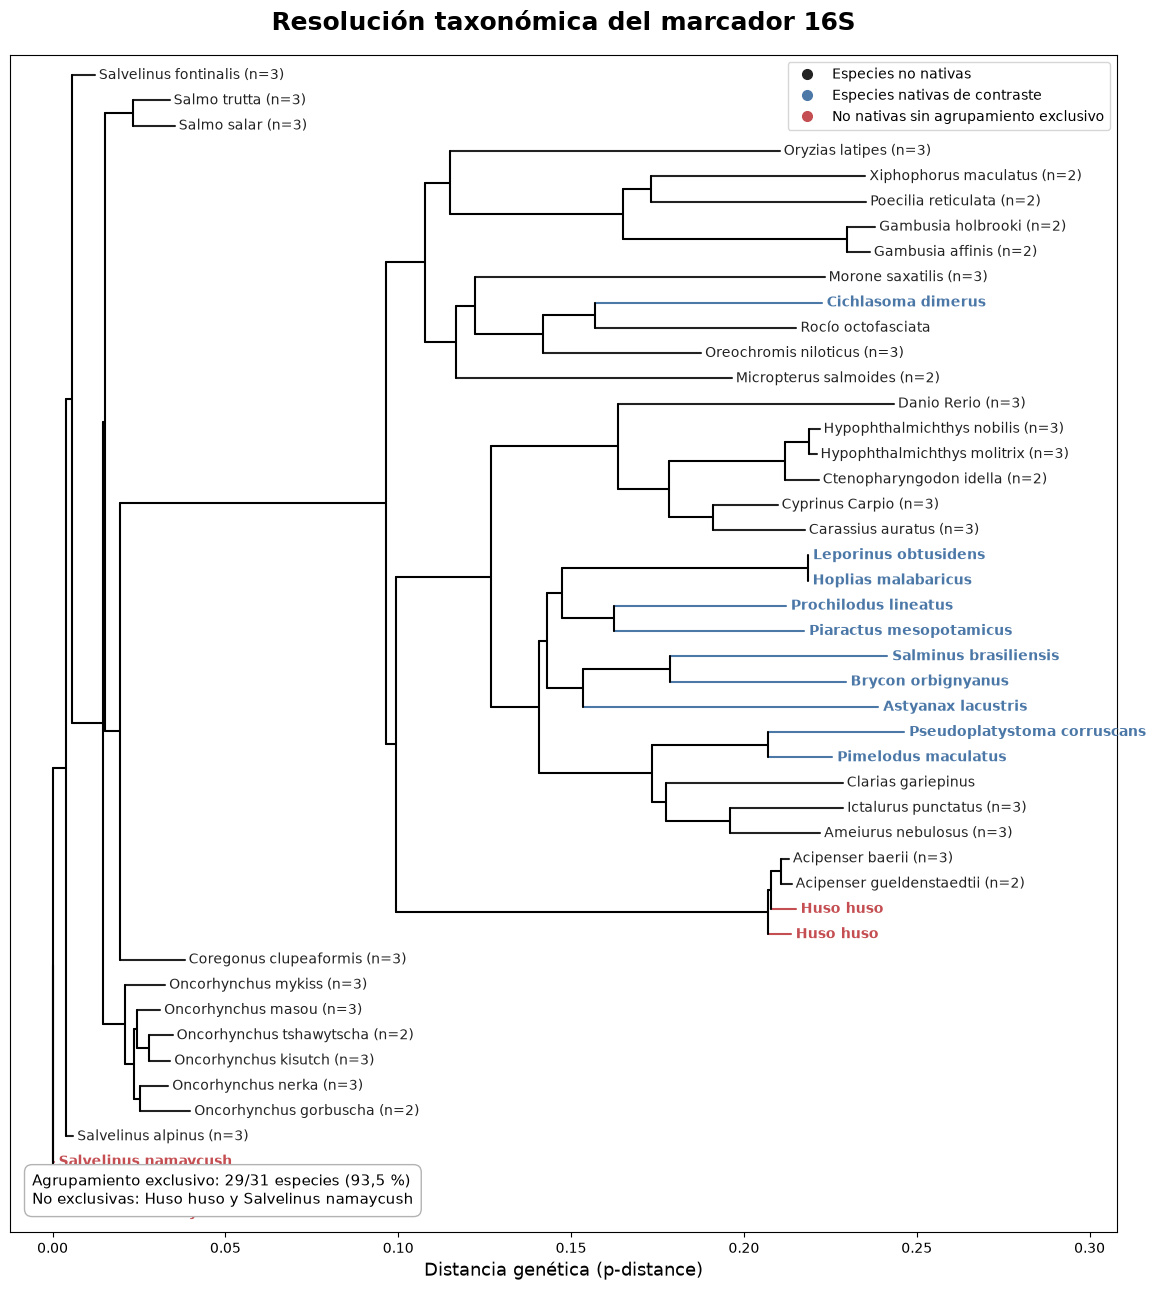

PNG: /home/matias-zabala/Descargas/Tesina/secuencias/Analisis/Figuras/seleccion_marcador/03_resolucion_taxonomica/arbol_NJ_16S_compacto_poster.png
PDF: /home/matias-zabala/Descargas/Tesina/secuencias/Analisis/Figuras/seleccion_marcador/03_resolucion_taxonomica/arbol_NJ_16S_compacto_poster.pdf


In [ ]:
# ==========================================
# ÁRBOL NJ 16S — VERSIÓN COMPACTA PÓSTER
# ==========================================

from Bio import Phylo
from matplotlib.lines import Line2D

# ------------------------------------------
# COLORES
# ------------------------------------------

COLOR_NO_NATIVA = "#222222"
COLOR_NATIVA = "#4C78A8"
COLOR_NO_EXCLUSIVA = "#C44E52"

no_exclusivas_16S = {
    "Huso huso",
    "Salvelinus namaycush"
}

especies_nativas_16S = {
    datos["especie"]
    for datos in mapa_16S.values()
    if datos["tipo"] == "nativa"
}


# ------------------------------------------
# FUNCIÓN PARA RECUPERAR ESPECIE
# ------------------------------------------

def especie_desde_etiqueta(etiqueta):

    etiqueta = etiqueta.strip()

    # Si está colapsada:
    # "Acipenser baerii (n=3)"
    if " (n=" in etiqueta:
        return etiqueta.split(" (n=")[0].strip()

    return etiqueta


# ------------------------------------------
# COLOREAR RAMAS TERMINALES
# ------------------------------------------

for terminal in arbol_16S_colapsado.get_terminals():

    especie = especie_desde_etiqueta(
        terminal.name
    )

    if especie in no_exclusivas_16S:
        terminal.color = COLOR_NO_EXCLUSIVA

    elif especie in especies_nativas_16S:
        terminal.color = COLOR_NATIVA

    else:
        terminal.color = COLOR_NO_NATIVA


# ------------------------------------------
# DIBUJAR
# ------------------------------------------

fig, ax = plt.subplots(
    figsize=(12, 13)
)

Phylo.draw(
    arbol_16S_colapsado,
    axes=ax,
    do_show=False,
    show_confidence=False,
    label_func=lambda clado:
        clado.name if clado.is_terminal() else None
)


# ------------------------------------------
# COLOREAR ETIQUETAS
# ------------------------------------------

for texto in ax.texts:

    etiqueta = texto.get_text().strip()

    if not etiqueta:
        continue

    especie = especie_desde_etiqueta(
        etiqueta
    )

    if especie in no_exclusivas_16S:

        texto.set_color(
            COLOR_NO_EXCLUSIVA
        )

        texto.set_fontweight(
            "bold"
        )

    elif especie in especies_nativas_16S:

        texto.set_color(
            COLOR_NATIVA
        )

        texto.set_fontweight(
            "bold"
        )

    else:

        texto.set_color(
            COLOR_NO_NATIVA
        )


# ------------------------------------------
# TÍTULO Y EJES
# ------------------------------------------

ax.set_title(
    "Resolución taxonómica del marcador 16S",
    fontsize=18,
    fontweight="bold",
    pad=18
)

ax.set_xlabel(
    "Distancia genética (p-distance)",
    fontsize=13
)

ax.set_ylabel("")

ax.tick_params(
    axis="x",
    labelsize=10
)

ax.tick_params(
    axis="y",
    left=False,
    labelleft=False
)


# ------------------------------------------
# RESULTADO PRINCIPAL
# ------------------------------------------

ax.text(
    0.02,
    0.02,
    "Agrupamiento exclusivo: 29/31 especies (93,5 %)\n"
    "No exclusivas: Huso huso y Salvelinus namaycush",
    transform=ax.transAxes,
    fontsize=11,
    verticalalignment="bottom",
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="white",
        edgecolor="0.7"
    )
)


# ------------------------------------------
# LEYENDA
# ------------------------------------------

leyenda = [

    Line2D(
        [0], [0],
        marker="o",
        linestyle="None",
        markerfacecolor=COLOR_NO_NATIVA,
        markeredgecolor=COLOR_NO_NATIVA,
        markersize=7,
        label="Especies no nativas"
    ),

    Line2D(
        [0], [0],
        marker="o",
        linestyle="None",
        markerfacecolor=COLOR_NATIVA,
        markeredgecolor=COLOR_NATIVA,
        markersize=7,
        label="Especies nativas de contraste"
    ),

    Line2D(
        [0], [0],
        marker="o",
        linestyle="None",
        markerfacecolor=COLOR_NO_EXCLUSIVA,
        markeredgecolor=COLOR_NO_EXCLUSIVA,
        markersize=7,
        label="No nativas sin agrupamiento exclusivo"
    )
]

ax.legend(
    handles=leyenda,
    loc="upper right",
    fontsize=10,
    frameon=True
)


# ------------------------------------------
# GUARDAR
# ------------------------------------------

plt.tight_layout()

carpeta_salida = (
    FIGURAS
    / "03_resolucion_taxonomica"
)

carpeta_salida.mkdir(
    parents=True,
    exist_ok=True
)

ruta_png = (
    carpeta_salida
    / "arbol_NJ_16S_compacto_poster.png"
)

ruta_pdf = (
    carpeta_salida
    / "arbol_NJ_16S_compacto_poster.pdf"
)

fig.savefig(
    ruta_png,
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    ruta_pdf,
    bbox_inches="tight"
)

plt.show()

print("PNG:", ruta_png)
print("PDF:", ruta_pdf)

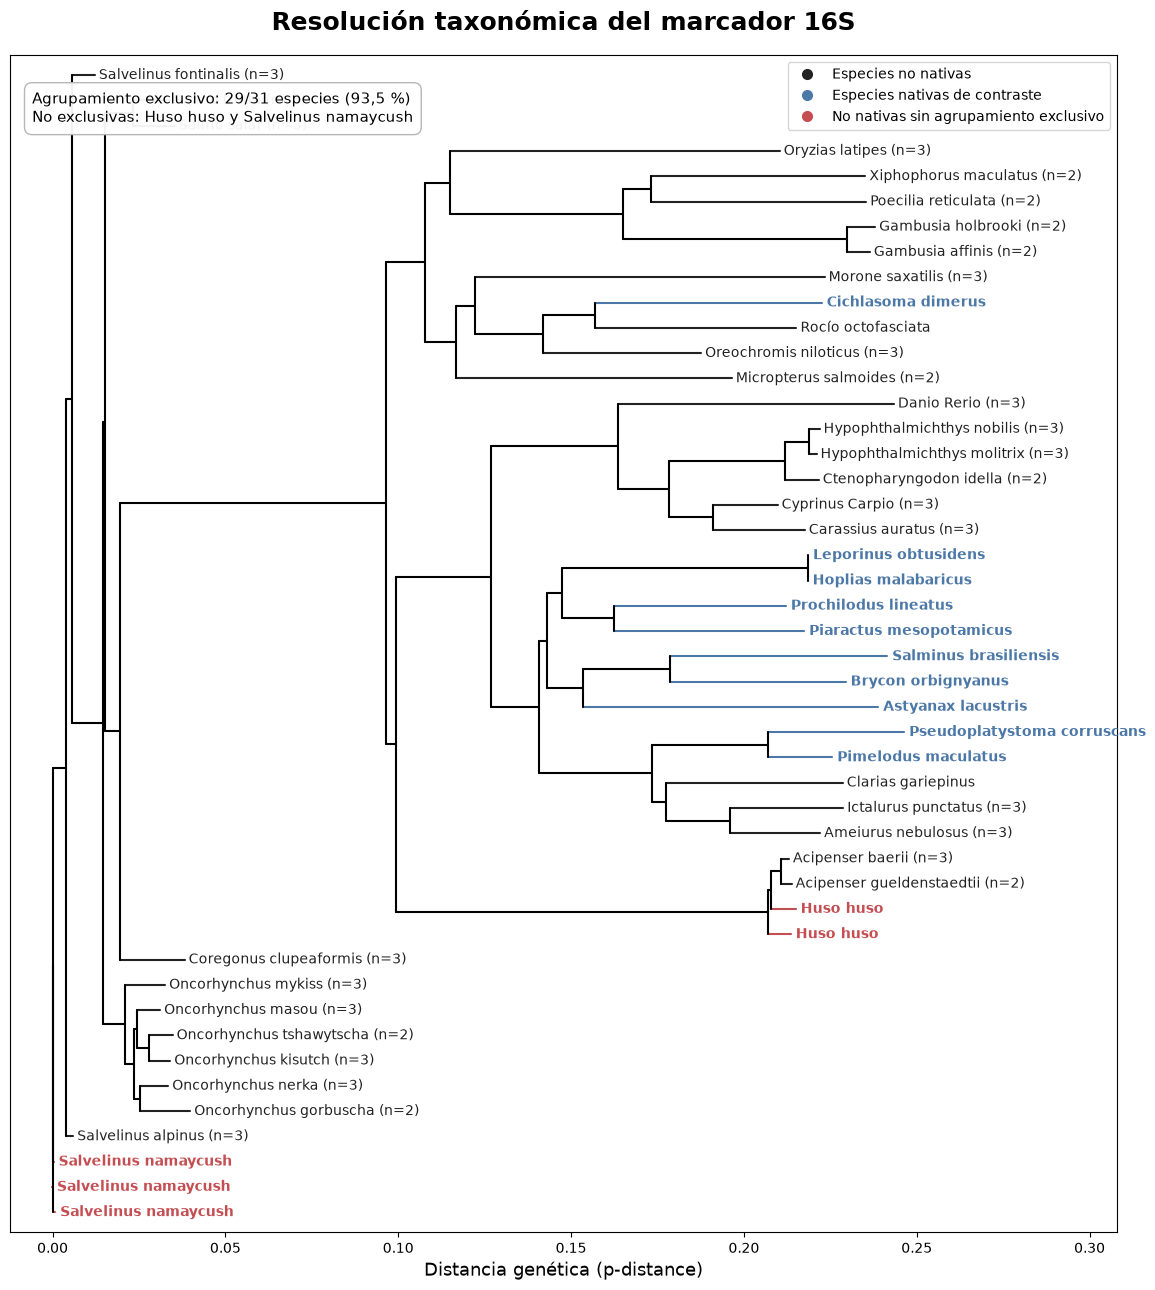

In [ ]:
# Mover el recuadro de resultados

# Eliminar el recuadro anterior
for texto in list(ax.texts):
    if texto.get_text().startswith("Agrupamiento exclusivo:"):
        texto.remove()

# Nuevo recuadro: arriba a la izquierda
ax.text(
    0.02,
    0.97,
    "Agrupamiento exclusivo: 29/31 especies (93,5 %)\n"
    "No exclusivas: Huso huso y Salvelinus namaycush",
    transform=ax.transAxes,
    fontsize=11,
    verticalalignment="top",
    horizontalalignment="left",
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="white",
        edgecolor="0.7",
        alpha=0.95
    )
)

# Volver a guardar
fig.savefig(
    ruta_png,
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    ruta_pdf,
    bbox_inches="tight"
)

display(fig)